# Olympic Medals vs Markets — Metric-Selectable Graph Builder

This notebook reads your result CSV files and creates **clean, intuitive graphs** using **one selected market metric per country**.

By default it uses:
- **United States** → `ret_SPY`
- **Norway** → `ret_OSEBX`

You can override those defaults in the configuration cell.

Design goal: every figure should compare **only one market metric** against **one medal-related concept** at a time.


In [169]:

from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

plt.rcParams["figure.dpi"] = 140
plt.rcParams["savefig.dpi"] = 220
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


In [170]:

RESULTS_DIRS = {
    "us": Path("../results/usa"),
    "norway": Path("../results/norway"),
    "nz": Path("../results/nz"),
}

RESULT_SUFFIXES = [
    "results_car_summary.csv",
    "results_core_regressions_long.csv",
    "results_corr_matrix.csv",
    "results_diff_in_means.csv",
    "results_lead_lag_long.csv",
    "results_season_interaction_long.csv",
    "results_sector_regressions_long.csv",
    "results_summary_stats.csv",
]

def discover_result_files():
    found = {}

    for prefix, dir_path in RESULTS_DIRS.items():
        found[prefix] = {}

        for suffix in RESULT_SUFFIXES:
            candidate = dir_path / suffix
            if candidate.exists():
                found[prefix][suffix] = candidate

    return found

result_files = discover_result_files()

print("Detected result groups:")


Detected result groups:


## Helper functions

In [171]:
def nice_country_name(prefix: str) -> str:
    return "United States" if prefix.lower() == "us" else prefix.replace("_", " ").title()

def load_group(prefix: str):
    return {suffix: pd.read_csv(path) for suffix, path in result_files[prefix].items()}

def ensure_fig_dir(prefix: str) -> Path:
    mapping = {
        "us": Path("../figures/us"),
        "norway": Path("../figures/norway"),
        "nz": Path("../figures/nz"),
    }
    out = mapping[prefix]
    out.mkdir(parents=True, exist_ok=True)
    return out

def save_show(fig, outpath: Path):
    fig.tight_layout()
    fig.savefig(outpath, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def stars(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def normal_approx_ci(row):
    se = pd.to_numeric(row.get("std_err", np.nan), errors="coerce")
    return np.nan if pd.isna(se) else 1.96 * se


# ---------- schema-aware helpers ----------

def extract_y_from_model(model_str):
    if pd.isna(model_str):
        return None
    s = str(model_str)
    return s.split("~")[0].strip() if "~" in s else None

def get_metric_series_from_df(df):
    metrics = set()

    if "y" in df.columns:
        metrics.update(df["y"].dropna().astype(str).tolist())

    if "model" in df.columns:
        lhs = df["model"].dropna().astype(str).map(extract_y_from_model)
        metrics.update([x for x in lhs if x])

    return metrics

def infer_available_metrics(data_dict):
    metrics = set()
    for key in [
        "results_core_regressions_long.csv",
        "results_lead_lag_long.csv",
        "results_season_interaction_long.csv",
        "results_diff_in_means.csv",
    ]:
        if key not in data_dict:
            continue
        df = data_dict[key]

        metrics.update(get_metric_series_from_df(df))

        if "metric" in df.columns:
            metrics.update(df["metric"].dropna().astype(str).tolist())

    return sorted(metrics)

DEFAULT_METRICS = {
    "us": "ret_SPY",
    "norway": "ret_OSEBX",
}

def choose_metric(prefix, available_metrics, user_selection=None):
    if user_selection and user_selection in available_metrics:
        return user_selection

    default_metric = DEFAULT_METRICS.get(prefix)
    if default_metric in available_metrics:
        return default_metric

    ret_like = [m for m in available_metrics if str(m).startswith("ret_")]
    return ret_like[0] if ret_like else (available_metrics[0] if available_metrics else None)

def infer_ticker_from_metric(metric: str):
    if not metric:
        return None
    m = re.match(r"^(?:abret_|ret_|vol_|volume_|log_volume_change_|lvc_)?(.+)$", str(metric))
    return m.group(1) if m else metric.replace("ret_", "").replace("abret_", "")

TERM_PRIORITY = ["performance_score", "any_medal_dummy", "total_medals", "gold", "silver", "bronze"]

def get_term_series_from_df(df):
    terms = set()

    if "term" in df.columns:
        terms.update(df["term"].dropna().astype(str).tolist())

    if "param" in df.columns:
        params = df["param"].dropna().astype(str)
        params = [p for p in params if p not in {"const", "winter_dummy"} and not p.startswith("dow_") and not p.startswith("month_")]
        terms.update(params)

    return terms

def choose_focus_term(df, user_term=None):
    terms = get_term_series_from_df(df)
    if user_term and user_term in terms:
        return user_term
    for term in TERM_PRIORITY:
        if term in terms:
            return term
    return sorted(list(terms))[0] if terms else None

def subset_metric_rows(df, metric):
    if df is None or df.empty or metric is None:
        return df.iloc[0:0].copy()

    if "y" in df.columns:
        return df[df["y"].astype(str) == str(metric)].copy()

    if "model" in df.columns:
        tmp = df.copy()
        tmp["y_inferred"] = tmp["model"].astype(str).map(extract_y_from_model)
        return tmp[tmp["y_inferred"].astype(str) == str(metric)].copy()

    if "metric" in df.columns:
        return df[df["metric"].astype(str) == str(metric)].copy()

    return df.iloc[0:0].copy()

def get_term_column(df):
    if "term" in df.columns:
        return "term"
    if "param" in df.columns:
        return "param"
    return None

def choose_single_model(df):
    if "model" not in df.columns or df.empty:
        return None

    model_series = df["model"].dropna().astype(str)
    if model_series.empty:
        return None

    preferred_patterns = [
        r"score \+ ctrls",
        r"lag1 \+ t \+ lead1 \+ ctrls",
        r"score \+ winter \+ interaction \+ ctrls",
    ]

    for pattern in preferred_patterns:
        pref = df[df["model"].astype(str).str.contains(pattern, regex=True, na=False)]
        if not pref.empty:
            if "p" in pref.columns:
                tmp = pref.copy()
                tmp["p_num"] = pd.to_numeric(tmp["p"], errors="coerce")
                valid = tmp.dropna(subset=["p_num"])
                if not valid.empty:
                    return valid.sort_values("p_num").iloc[0]["model"]
            return pref.iloc[0]["model"]

    if "p" in df.columns:
        tmp = df.copy()
        tmp["p_num"] = pd.to_numeric(tmp["p"], errors="coerce")
        valid = tmp.dropna(subset=["p_num"])
        if not valid.empty:
            return valid.sort_values("p_num").iloc[0]["model"]

    return model_series.iloc[0]

def lead_lag_event_time(term, focus_term):
    t = str(term)

    if focus_term == "performance_score":
        if "score_lag" in t:
            m = re.search(r"score_lag(\d+)", t)
            return -int(m.group(1)) if m else np.nan
        if "score_lead" in t:
            m = re.search(r"score_lead(\d+)", t)
            return int(m.group(1)) if m else np.nan
        if t == "performance_score":
            return 0

    if focus_term == "any_medal_dummy":
        if "any_lag" in t or "medal_lag" in t:
            m = re.search(r"(?:any|medal)_lag(\d+)", t)
            return -int(m.group(1)) if m else np.nan
        if "any_lead" in t or "medal_lead" in t:
            m = re.search(r"(?:any|medal)_lead(\d+)", t)
            return int(m.group(1)) if m else np.nan
        if t == "any_medal_dummy":
            return 0

    if focus_term == "total_medals":
        if "total_lag" in t:
            m = re.search(r"total_lag(\d+)", t)
            return -int(m.group(1)) if m else np.nan
        if "total_lead" in t:
            m = re.search(r"total_lead(\d+)", t)
            return int(m.group(1)) if m else np.nan
        if t == "total_medals":
            return 0

    for base in ["gold", "silver", "bronze"]:
        if focus_term == base:
            if f"{base}_lag" in t:
                m = re.search(rf"{base}_lag(\d+)", t)
                return -int(m.group(1)) if m else np.nan
            if f"{base}_lead" in t:
                m = re.search(rf"{base}_lead(\d+)", t)
                return int(m.group(1)) if m else np.nan
            if t == base:
                return 0

    return np.nan

def standardize_car_summary(car_df):
    """
    Returns a long-format CAR table with columns:
    ticker, window, mean_car, n_events, t_stat_vs_0
    Works for:
    - Norway long format
    - US wide format
    """
    if car_df is None or car_df.empty:
        return pd.DataFrame(columns=["ticker", "window", "mean_car", "n_events", "t_stat_vs_0"])

    car = car_df.copy()

    # already long
    if {"ticker", "window", "mean_car"}.issubset(car.columns):
        for col in ["n_events", "t_stat_vs_0"]:
            if col not in car.columns:
                car[col] = np.nan
        return car[["ticker", "window", "mean_car", "n_events", "t_stat_vs_0"]].copy()

    # wide US format
    if "ticker" in car.columns:
        mean_cols = [c for c in car.columns if c.startswith("CAR_") and c.endswith("_mean")]
        rows = []

        for _, r in car.iterrows():
            ticker = r["ticker"]
            for mc in mean_cols:
                window = mc.replace("CAR_", "").replace("_mean", "")
                n_col = f"CAR_{window}_n"
                rows.append({
                    "ticker": ticker,
                    "window": window,
                    "mean_car": pd.to_numeric(r.get(mc, np.nan), errors="coerce"),
                    "n_events": pd.to_numeric(r.get(n_col, np.nan), errors="coerce"),
                    "t_stat_vs_0": np.nan,
                })

        return pd.DataFrame(rows)

    return pd.DataFrame(columns=["ticker", "window", "mean_car", "n_events", "t_stat_vs_0"])

def build_summary_table(summary_records, outpath):
    if not summary_records:
        return
    sdf = pd.DataFrame(summary_records)
    fig, ax = plt.subplots(figsize=(12, max(2.5, 0.45 * len(sdf) + 1)))
    ax.axis("off")
    display_df = sdf.copy()
    for c in ["value", "p_value"]:
        if c in display_df.columns:
            display_df[c] = display_df[c].map(lambda x: "" if pd.isna(x) else f"{x:.4f}")
    table = ax.table(
        cellText=display_df.values,
        colLabels=display_df.columns,
        loc="center",
        cellLoc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.4)
    ax.set_title("Key Findings Summary", pad=16)
    save_show(fig, outpath)

## Metric and term selection

Set a metric override for any country if you want a different graph set.  
Leave as `None` to use the defaults (`ret_SPY` for US and `ret_OSEBX` for Norway).

You can also optionally force one medal variable, otherwise the notebook picks a clean default:
- `performance_score`
- `any_medal_dummy`
- `total_medals`
- `gold`
- `silver`
- `bronze`


In [172]:

USER_METRIC_SELECTION = {
    "us": None,        
    "norway": None, 
}

USER_TERM_SELECTION = {
    "us": None,     
    "norway": None,   
}


In [173]:
country_config = {}

for prefix in sorted(result_files):
    data = load_group(prefix)
    available_metrics = infer_available_metrics(data)
    selected_metric = choose_metric(prefix, available_metrics, USER_METRIC_SELECTION.get(prefix))

    selected_term = None
    if "results_core_regressions_long.csv" in data and selected_metric is not None:
        core = data["results_core_regressions_long.csv"].copy()
        core_metric = subset_metric_rows(core, selected_metric)

        if not core_metric.empty:
            selected_term = choose_focus_term(core_metric, USER_TERM_SELECTION.get(prefix))

    # fallback to lead/lag if core did not work
    if selected_term is None and "results_lead_lag_long.csv" in data and selected_metric is not None:
        lead = data["results_lead_lag_long.csv"].copy()
        lead_metric = subset_metric_rows(lead, selected_metric)
        if not lead_metric.empty:
            selected_term = choose_focus_term(lead_metric, USER_TERM_SELECTION.get(prefix))

    country_config[prefix] = {
        "country": nice_country_name(prefix),
        "metric": selected_metric,
        "ticker": infer_ticker_from_metric(selected_metric),
        "term": selected_term,
        "available_metrics": available_metrics,
    }

for prefix, cfg in country_config.items():
    print(f"\n[{prefix}] {cfg['country']}")
    print("Selected metric:", cfg["metric"])
    print("Selected ticker:", cfg["ticker"])
    print("Selected medal variable:", cfg["term"])
    print("Available metrics:", cfg["available_metrics"])


[norway] Norway
Selected metric: ret_OSEBX
Selected ticker: OSEBX
Selected medal variable: performance_score
Available metrics: ['absret_OSEBX', 'lvc_OSEBX', 'ret_OSEBX', 'vol20_OSEBX']

[nz] Nz
Selected metric: ret_NZ50
Selected ticker: NZ50
Selected medal variable: performance_score
Available metrics: ['absret_NZ50', 'lvc_NZ50', 'ret_NZ50', 'vol20_NZ50']

[us] United States
Selected metric: ret_SPY
Selected ticker: SPY
Selected medal variable: performance_score
Available metrics: ['abret_ff3_DKNG', 'abret_ff3_NKE', 'abret_ff3_XLY', 'absret_SPY', 'lvc_SPY', 'ret_SPY', 'vol20_SPY']


## 1. CAR summary for the selected market ticker

This keeps the event-study chart focused on **one ticker / market proxy** per country.


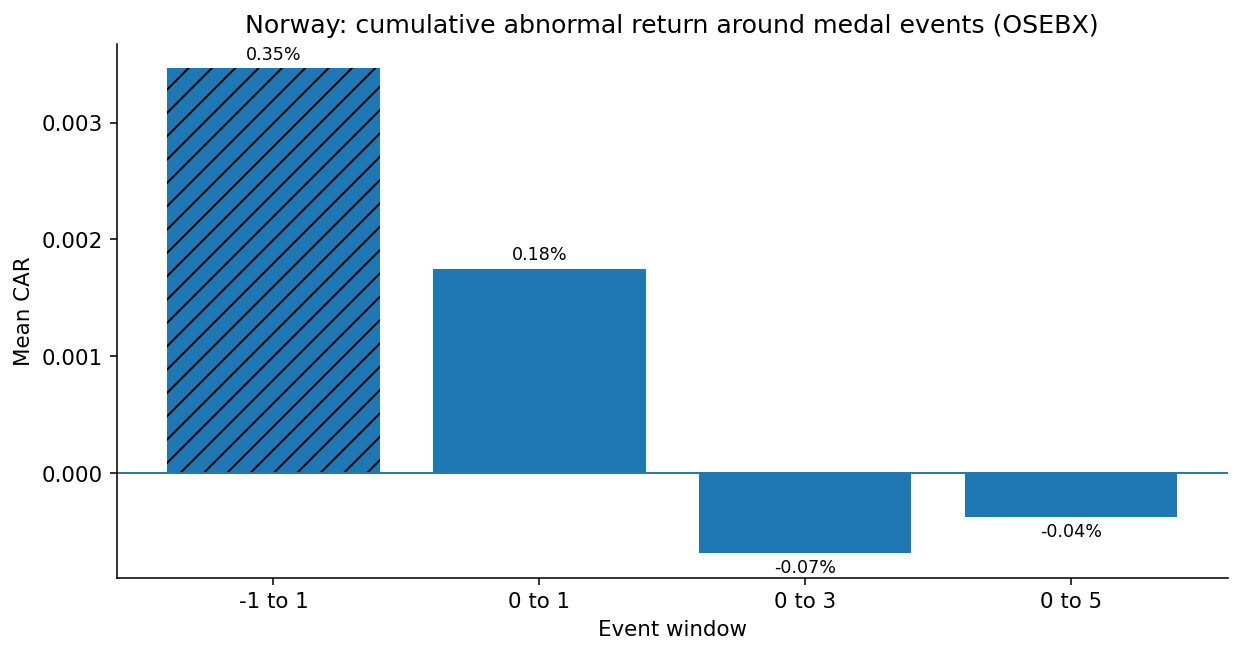

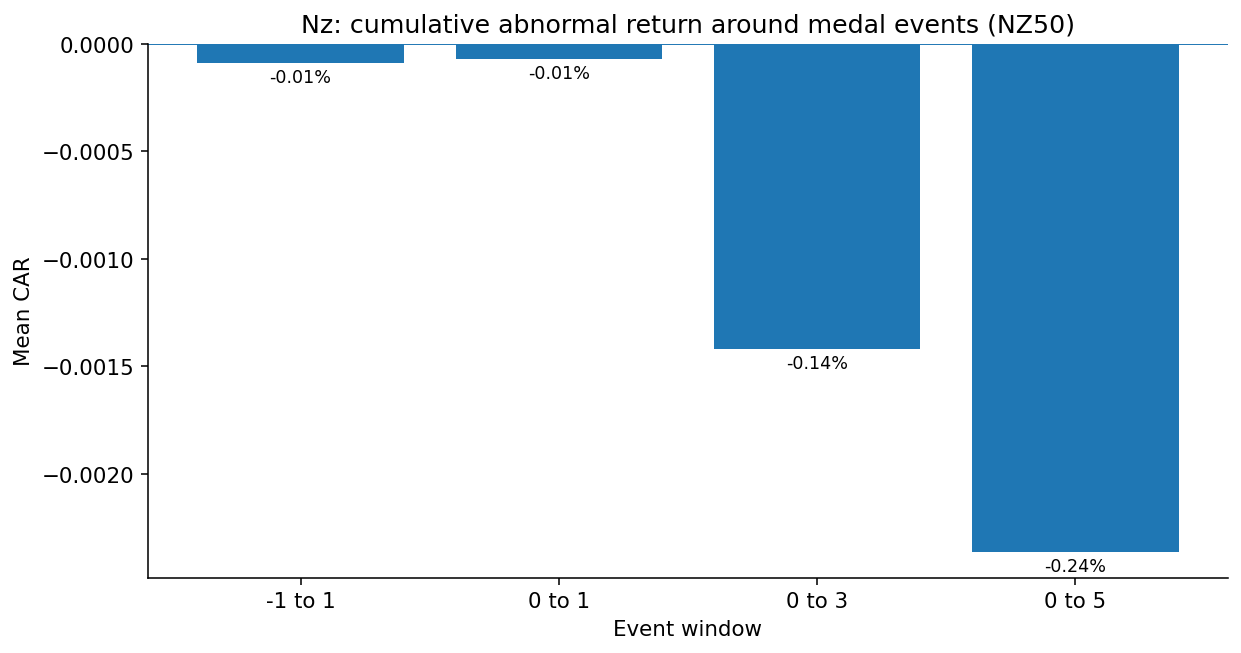

In [174]:

all_summary_rows = []

for prefix in sorted(result_files):
    cfg = country_config[prefix]
    country = cfg["country"]
    ticker = cfg["ticker"]
    data = load_group(prefix)
    fig_dir = ensure_fig_dir(prefix)

    if "results_car_summary.csv" not in data or ticker is None:
        continue

    car = data["results_car_summary.csv"].copy()
    if not {"ticker", "window", "mean_car"}.issubset(car.columns):
        continue

    car_plot = car[car["ticker"].astype(str) == str(ticker)].copy()
    if car_plot.empty:
        continue

    car_plot["sig"] = car_plot["t_stat_vs_0"].abs() >= 1.96 if "t_stat_vs_0" in car_plot.columns else False

    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.bar(car_plot["window"], car_plot["mean_car"])
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{country}: cumulative abnormal return around medal events ({ticker})")
    ax.set_xlabel("Event window")
    ax.set_ylabel("Mean CAR")

    ymin, ymax = ax.get_ylim()
    offset = (ymax - ymin) * 0.01
    for patch, (_, row) in zip(ax.patches, car_plot.iterrows()):
        if row.get("sig", False):
            patch.set_hatch("//")
        h = patch.get_height()
        x = patch.get_x() + patch.get_width() / 2
        y = h + offset if h >= 0 else h - offset
        va = "bottom" if h >= 0 else "top"
        ax.text(x, y, f"{h:.2%}", ha="center", va=va, fontsize=9)

    save_show(fig, fig_dir / f"{prefix}_01_car_summary_{ticker}.png")

    strongest = car_plot.loc[car_plot["mean_car"].abs().idxmax()]
    all_summary_rows.append({
        "country": country,
        "figure": "CAR summary",
        "metric": ticker,
        "focus": strongest["window"],
        "value": strongest["mean_car"],
        "p_value": np.nan,
        "note": f"t-stat vs 0 = {strongest.get('t_stat_vs_0', np.nan):.2f}"
    })


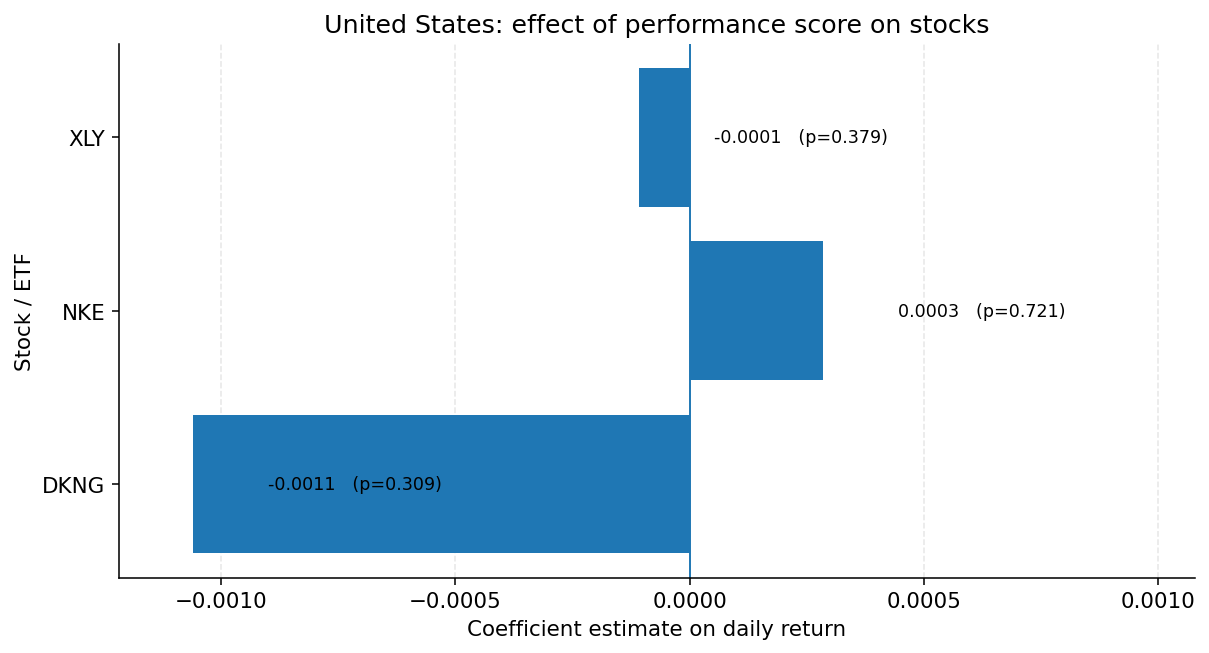

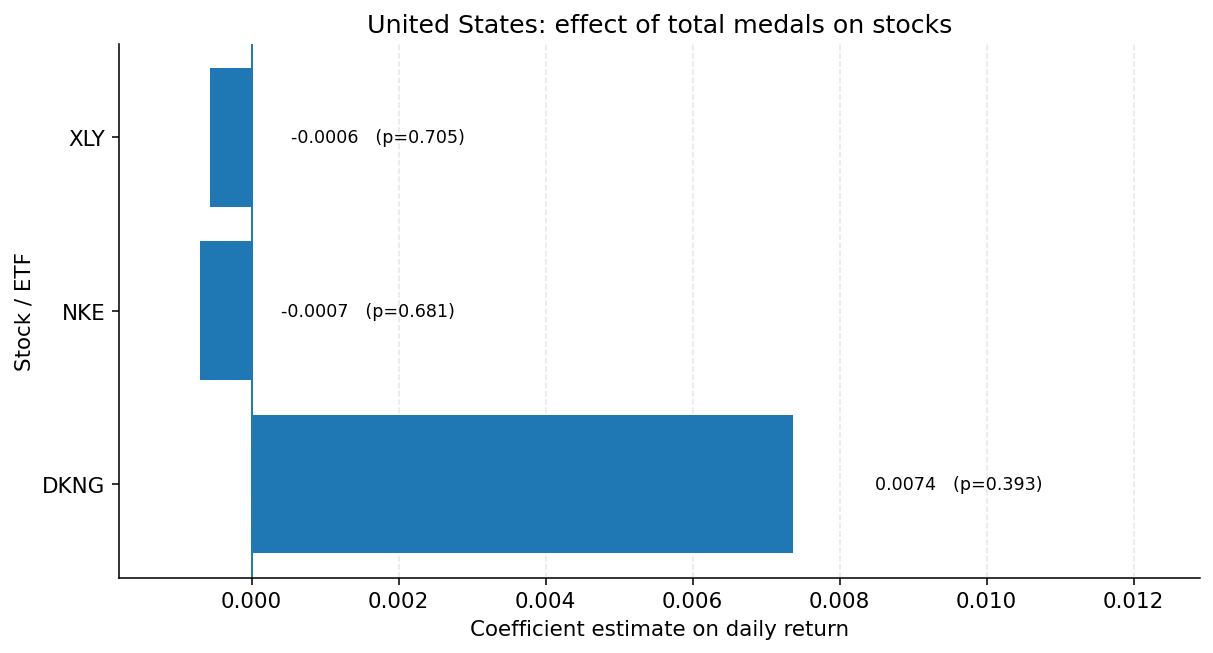

In [175]:
us_files = result_files["us"]
sec = pd.read_csv(us_files["results_sector_regressions_long.csv"]).copy()

sec["coef"] = pd.to_numeric(sec["coef"], errors="coerce")
sec["p"] = pd.to_numeric(sec["p"], errors="coerce")

prefix = "us"
fig_dir = ensure_fig_dir(prefix)

def stars(p):
    if pd.isna(p):
        return ""
    if p < 0.01:
        return "***"
    if p < 0.05:
        return "**"
    if p < 0.10:
        return "*"
    return ""

def stock_name_from_model(model_str):
    lhs = str(model_str).split("~")[0].strip()
    lhs = lhs.replace("ret_", "").replace("abret_ff3_", "")
    return lhs

def build_stock_effect_df(sec_df, variable, model_pattern, lhs_prefix="ret_"):
    out = sec_df.copy()

    out = out[
        out["model"].astype(str).str.startswith(lhs_prefix, na=False) &
        out["model"].astype(str).str.contains(model_pattern, regex=True, na=False) &
        (out["param"].astype(str) == variable)
    ].copy()

    if out.empty:
        return out

    out["stock"] = out["model"].map(stock_name_from_model)

    out = (
        out.sort_values(["stock", "p"], na_position="last")
           .drop_duplicates(subset="stock", keep="first")
           .reset_index(drop=True)
    )

    return out[["stock", "coef", "p", "model"]].copy()


def plot_stock_effects(df, title, xlabel, outname):
    if df.empty:
        print(f"No rows found for: {title}")
        return

    fig, ax = plt.subplots(figsize=(8.8, max(4.8, 0.7 * len(df))))

    ax.barh(df["stock"], df["coef"])
    ax.axvline(0, linewidth=1)

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Stock / ETF")

    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)
    ax.ticklabel_format(axis="x", style="plain")

    coef_min = df["coef"].min()
    coef_max = df["coef"].max()
    span = max(abs(coef_min), abs(coef_max))

    if span == 0 or pd.isna(span):
        span = 0.001

    left_pad = span * 0.15
    right_pad = span * 0.75
    ax.set_xlim(coef_min - left_pad, coef_max + right_pad)

    label_offset = span * 0.15

    for y_i, (_, row) in enumerate(df.iterrows()):
        coef = row["coef"]
        pval = row["p"]

        x_pos = coef + label_offset
        label = f"{coef:.4f}   (p={pval:.3f}{stars(pval)})" if pd.notna(pval) else f"{coef:.4f}"

        ax.text(
            x_pos,
            y_i,
            label,
            ha="left",
            va="center",
            fontsize=9,
            color="black"
        )

    save_show(fig, fig_dir / outname)


# ---------------------------------------------------
# Build both datasets first
# ---------------------------------------------------

score_df = build_stock_effect_df(
    sec_df=sec,
    variable="performance_score",
    model_pattern=r"score \+ ctrls",
    lhs_prefix="ret_"
)

medals_df = build_stock_effect_df(
    sec_df=sec,
    variable="total_medals",
    model_pattern=r"total\+score \+ ctrls",
    lhs_prefix="ret_"
)

# ---------------------------------------------------
# Force the same stock ordering in both graphs
# ---------------------------------------------------

stock_order = sorted(set(score_df["stock"]).union(set(medals_df["stock"])))

score_df["stock"] = pd.Categorical(score_df["stock"], categories=stock_order, ordered=True)
medals_df["stock"] = pd.Categorical(medals_df["stock"], categories=stock_order, ordered=True)

score_df = score_df.sort_values("stock")
medals_df = medals_df.sort_values("stock")

# ---------------------------------------------------
# Plot
# ---------------------------------------------------

plot_stock_effects(
    df=score_df,
    title="United States: effect of performance score on stocks",
    xlabel="Coefficient estimate on daily return",
    outname=f"{prefix}_01_stock_effect_performance_score.png"
)

plot_stock_effects(
    df=medals_df,
    title="United States: effect of total medals on stocks",
    xlabel="Coefficient estimate on daily return",
    outname=f"{prefix}_02_stock_effect_total_medals.png"
)

## 2. Medal days vs non-medal days for the selected metric

This chart always compares only **two bars**:
- selected metric on medal days
- selected metric on non-medal days


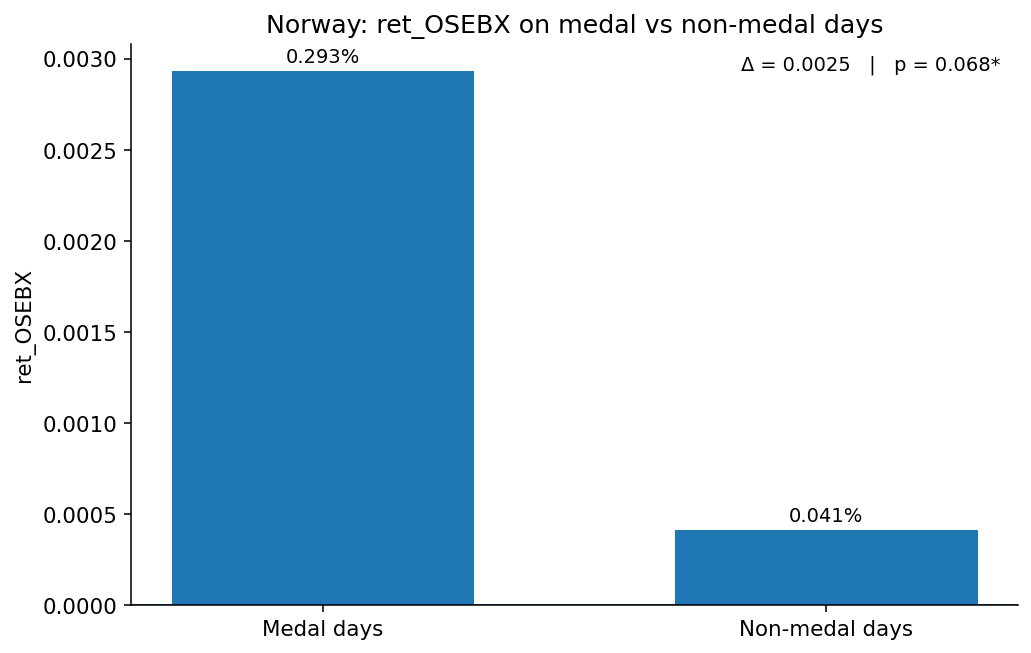

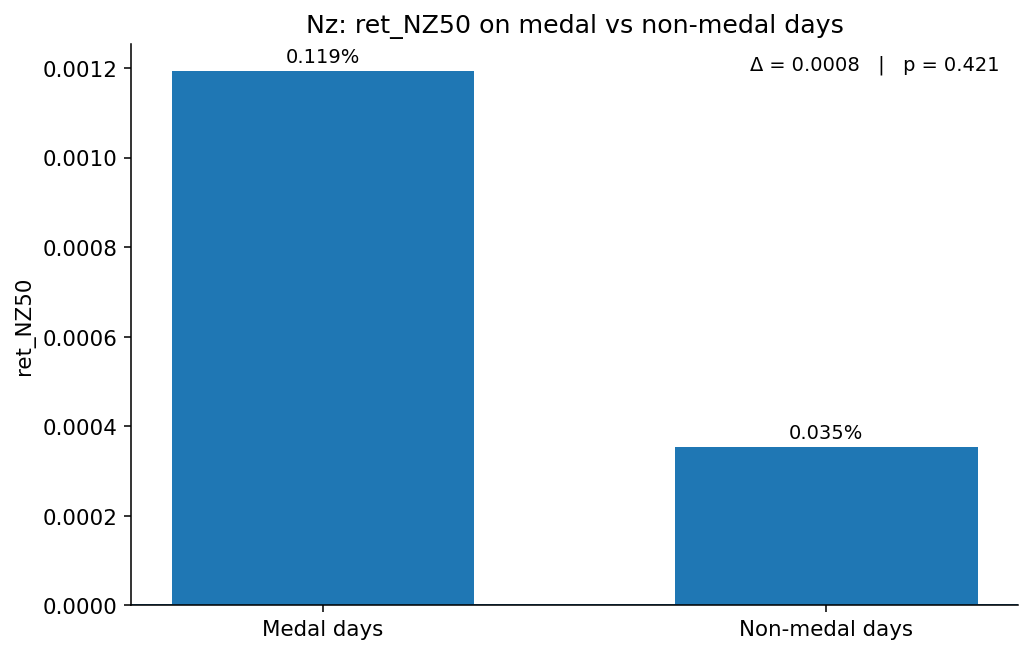

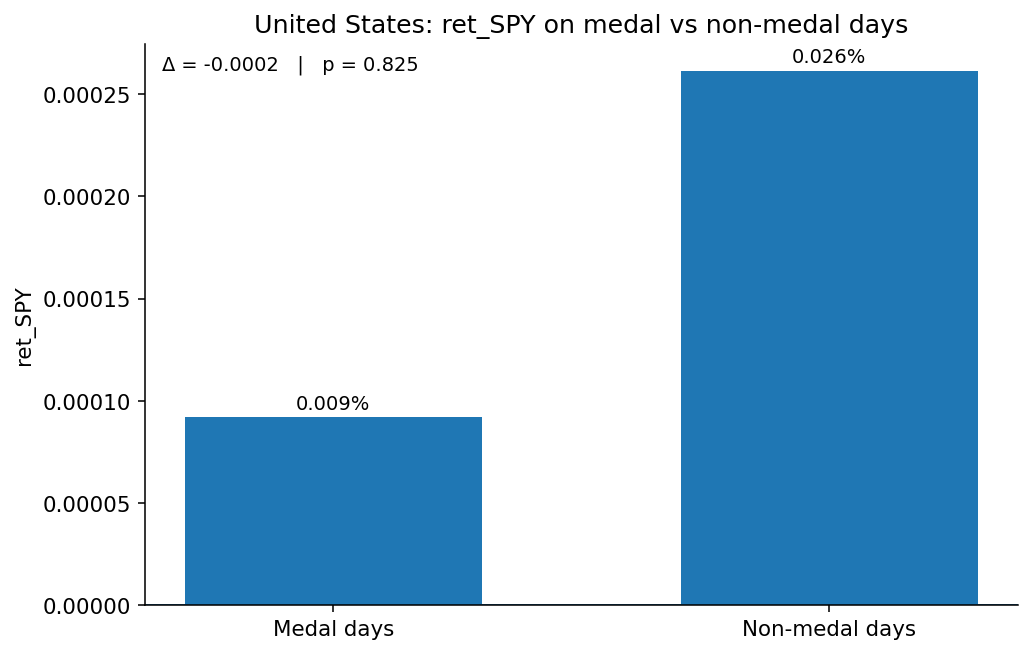

In [176]:

for prefix in sorted(result_files):
    cfg = country_config[prefix]
    country = cfg["country"]
    metric = cfg["metric"]
    data = load_group(prefix)
    fig_dir = ensure_fig_dir(prefix)

    if "results_diff_in_means.csv" not in data or metric is None:
        continue

    diff = data["results_diff_in_means.csv"].copy()
    req = {"metric", "mean_medal", "mean_nonmedal"}
    if not req.issubset(diff.columns):
        continue

    diff_plot = diff[diff["metric"].astype(str) == str(metric)].copy()
    if diff_plot.empty:
        continue

    row = diff_plot.iloc[0]
    p_num = pd.to_numeric(row.get("p", np.nan), errors="coerce")
    diff_num = pd.to_numeric(row.get("diff", np.nan), errors="coerce")

    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    labels = ["Medal days", "Non-medal days"]
    values = [row["mean_medal"], row["mean_nonmedal"]]
    ax.bar(labels, values, width=0.6)
    ax.axhline(0, linewidth=1)
    ax.set_ylabel(metric)
    ax.set_title(f"{country}: {metric} on medal vs non-medal days")

    ymin, ymax = ax.get_ylim()
    offset = (ymax - ymin) * 0.008
    for i, v in enumerate(values):
        y = v + offset if v >= 0 else v - offset
        va = "bottom" if v >= 0 else "top"
        label = f"{v:.3%}" if abs(v) < 1 else f"{v:.3f}"
        ax.text(i, y, label, ha="center", va=va, fontsize=10)

    note = f"Δ = {diff_num:.4f}" if pd.notna(diff_num) else "Δ = NA"
    if pd.notna(p_num):
        note += f"   |   p = {p_num:.3f}{stars(p_num)}"

    # place annotation differently by country
    if prefix == "us":
        x_pos = 0.02
        align = "left"
    else:  # Norway
        x_pos = 0.98
        align = "right"

    ax.text(
        x_pos,
        0.98,
        note,
        transform=ax.transAxes,
        ha=align,
        va="top",
        fontsize=10
    )

    if prefix == "us":
        save_show(fig, fig_dir / f"{prefix}_03_diff_in_means_{metric}.png")
    else:
        save_show(fig, fig_dir / f"{prefix}_02_diff_in_means_{metric}.png")

    all_summary_rows.append({
        "country": country,
        "figure": "Difference in means",
        "metric": metric,
        "focus": "medal vs non-medal",
        "value": diff_num,
        "p_value": p_num,
        "note": "Difference: medal minus non-medal"
    })


## 3. Timing of the reaction for the selected metric and medal variable

This uses the selected metric and one medal variable family, then plots how the effect changes
before, on, and after the medal event.


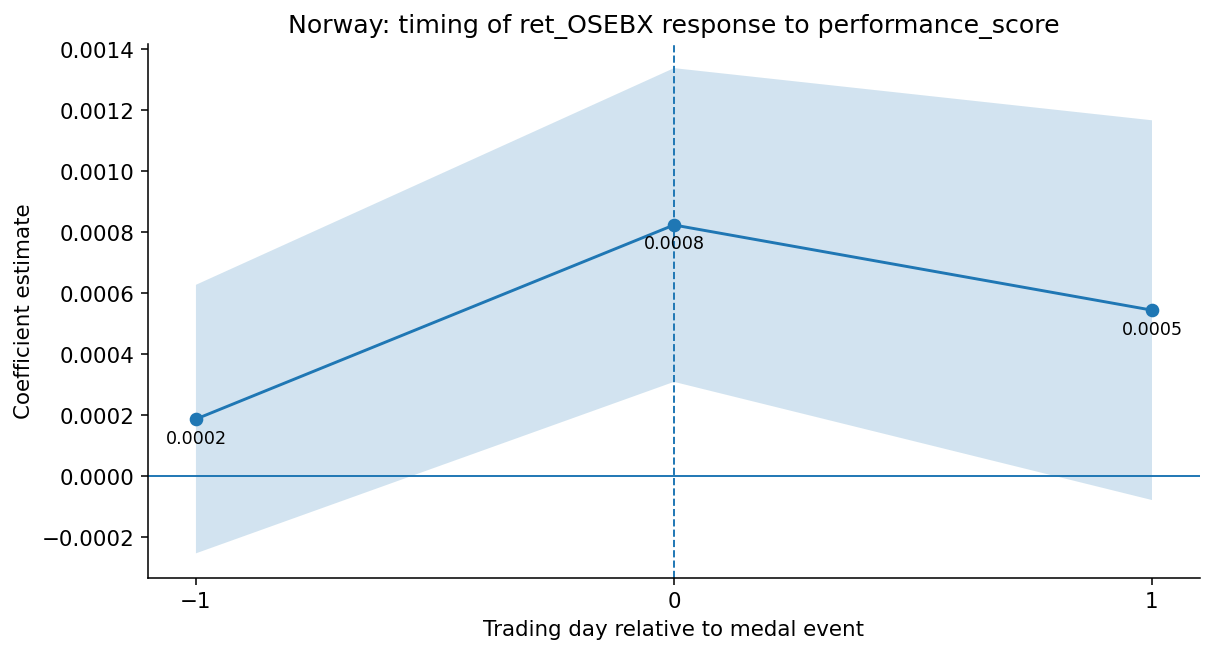

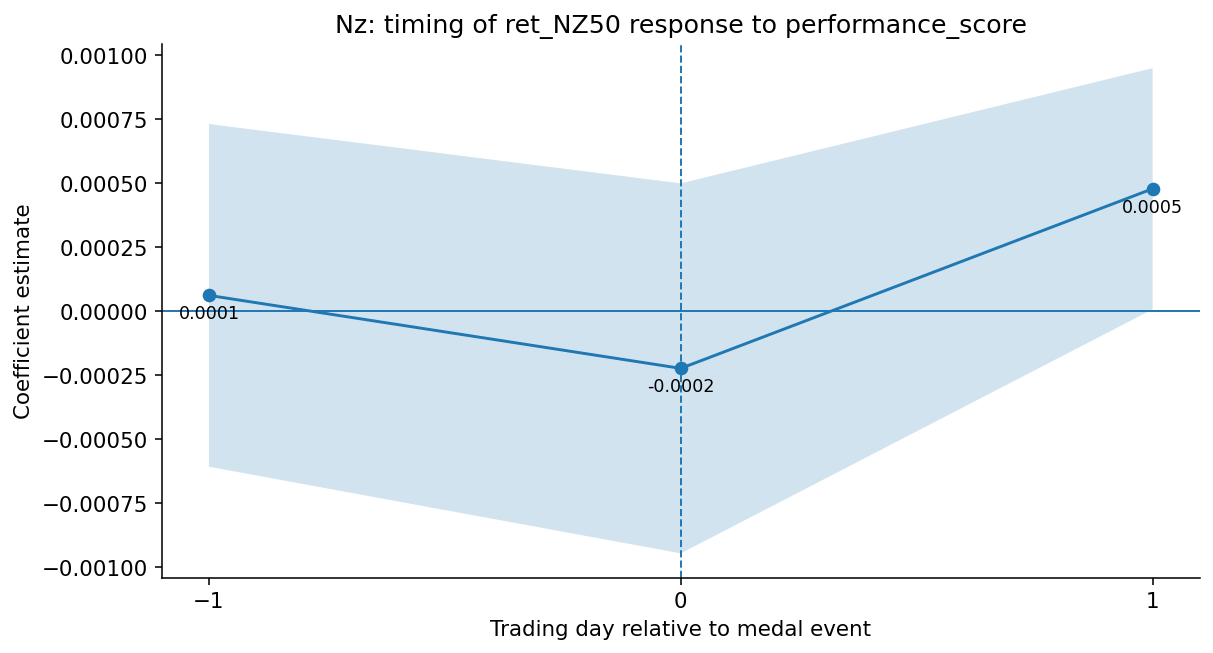

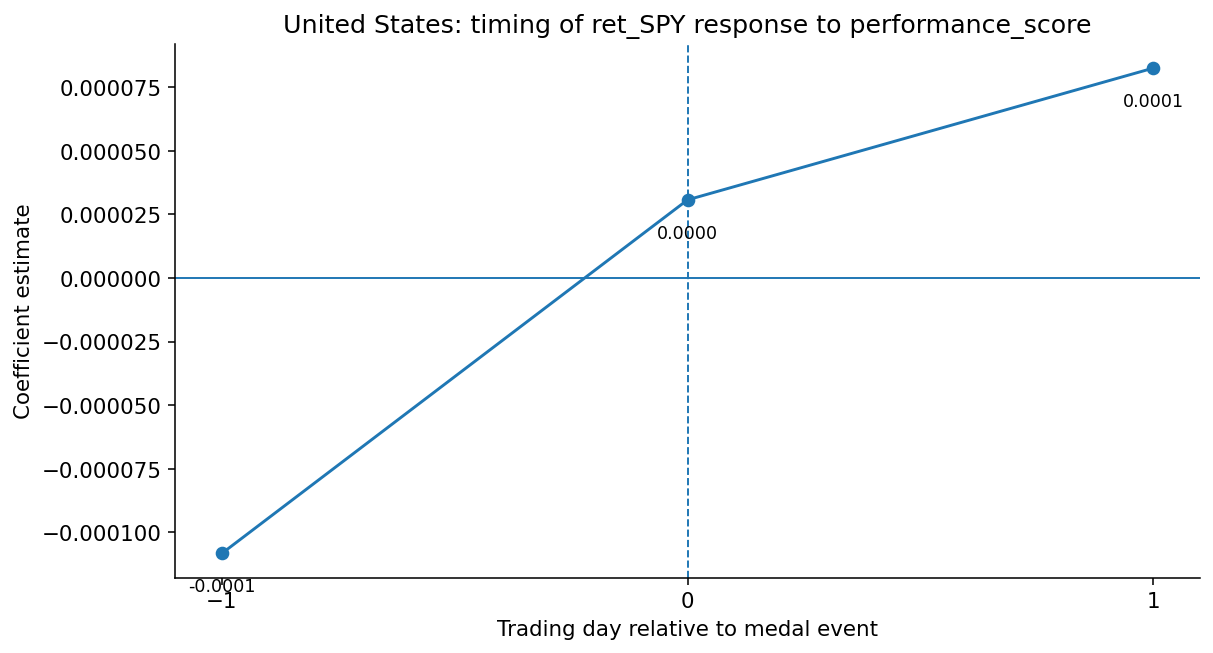

In [177]:
for prefix in sorted(result_files):
    cfg = country_config[prefix]
    country = cfg["country"]
    metric = cfg["metric"]
    focus_term = cfg["term"]
    data = load_group(prefix)
    fig_dir = ensure_fig_dir(prefix)

    if "results_lead_lag_long.csv" not in data or metric is None or focus_term is None:
        continue

    lead = data["results_lead_lag_long.csv"].copy()
    term_col = get_term_column(lead)

    if term_col is None or "coef" not in lead.columns:
        continue

    lead_plot = subset_metric_rows(lead, metric)
    if lead_plot.empty:
        continue

    lead_plot["event_time"] = lead_plot[term_col].map(lambda t: lead_lag_event_time(t, focus_term))
    lead_plot = lead_plot.dropna(subset=["event_time"]).copy()
    if lead_plot.empty:
        continue

    chosen_model = choose_single_model(lead_plot)
    if chosen_model is not None and "model" in lead_plot.columns:
        lead_plot = lead_plot[lead_plot["model"].astype(str) == str(chosen_model)].copy()

    if lead_plot.empty:
        continue

    lead_plot["coef"] = pd.to_numeric(lead_plot["coef"], errors="coerce")
    lead_plot["p_num"] = pd.to_numeric(lead_plot.get("p", np.nan), errors="coerce")
    lead_plot["std_err_num"] = pd.to_numeric(lead_plot.get("std_err", np.nan), errors="coerce")
    lead_plot = lead_plot.sort_values("event_time")

    fig, ax = plt.subplots(figsize=(8.8, 4.8))
    ci = 1.96 * lead_plot["std_err_num"] if "std_err_num" in lead_plot.columns else np.nan

    ax.plot(lead_plot["event_time"], lead_plot["coef"], marker="o")

    coef_range = lead_plot["coef"].max() - lead_plot["coef"].min()
    y_offset = coef_range * 0.05 if pd.notna(coef_range) and coef_range > 0 else 0.0002

    for x, y in zip(lead_plot["event_time"], lead_plot["coef"]):
        if pd.notna(y):
            ax.text(
                x,
                y - y_offset,
                f"{y:.4f}",
                ha="center",
                va="top",
                fontsize=9
            )

    if lead_plot["std_err_num"].notna().any():
        ax.fill_between(
            lead_plot["event_time"],
            lead_plot["coef"] - ci,
            lead_plot["coef"] + ci,
            alpha=0.2
        )

    ax.axhline(0, linewidth=1)
    ax.axvline(0, linestyle="--", linewidth=1)
    ax.set_xticks(sorted(lead_plot["event_time"].astype(int).unique()))
    ax.set_xlabel("Trading day relative to medal event")
    ax.set_ylabel("Coefficient estimate")
    ax.set_title(f"{country}: timing of {metric} response to {focus_term}")

    if prefix == "us":
        save_show(fig, fig_dir / f"{prefix}_04_lead_lag_{metric}_{focus_term}.png")
    else:
        save_show(fig, fig_dir / f"{prefix}_03_lead_lag_{metric}_{focus_term}.png")

    valid = lead_plot.dropna(subset=["p_num"])
    best = valid.loc[valid["p_num"].idxmin()] if not valid.empty else lead_plot.loc[lead_plot["coef"].abs().idxmax()]
    all_summary_rows.append({
        "country": country,
        "figure": "Lead / lag",
        "metric": metric,
        "focus": focus_term,
        "value": best["coef"],
        "p_value": best.get("p_num", np.nan),
        "note": f"event_time={int(best['event_time'])}"
    })

## 5. Season / winter interaction for the selected metric

This keeps the seasonal chart focused on the selected metric and a small set of directly relevant interaction terms.



 Norway ret_OSEBX
overall: 0.0007617583209998 summer: 0.0008577793843619 winter: 0.000520282743007
core y values: ['ret_OSEBX' 'lvc_OSEBX' 'absret_OSEBX' 'vol20_OSEBX']
core term values: ['const' 'any_medal_dummy' 'dow_1' 'dow_2' 'dow_3' 'dow_4' 'month_2'
 'month_3' 'month_4' 'month_5' 'month_6' 'month_7' 'month_8' 'month_9'
 'month_10' 'month_11' 'month_12' 'performance_score' 'gold' 'silver']
season y values: ['ret_OSEBX' 'lvc_OSEBX' 'absret_OSEBX' 'vol20_OSEBX']
season term values: ['const' 'performance_score' 'winter_dummy' 'score_x_winter' 'dow_1'
 'dow_2' 'dow_3' 'dow_4' 'month_2' 'month_3' 'month_4' 'month_5' 'month_6'
 'month_7' 'month_8' 'month_9' 'month_10' 'month_11' 'month_12']


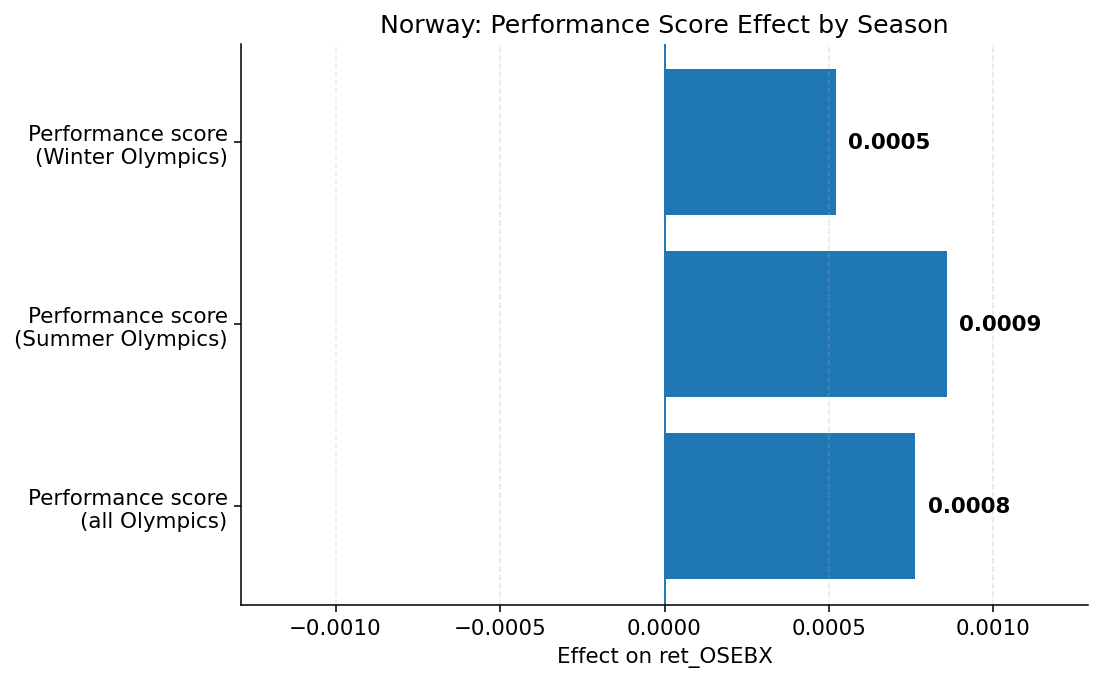


 United States ret_SPY
overall: 2.661779078319323e-06 summer: -3.805237752425244e-05 winter: 0.0008269421287352476
core y values: no y col
core term values: no term col
season y values: no y col
season term values: no term col


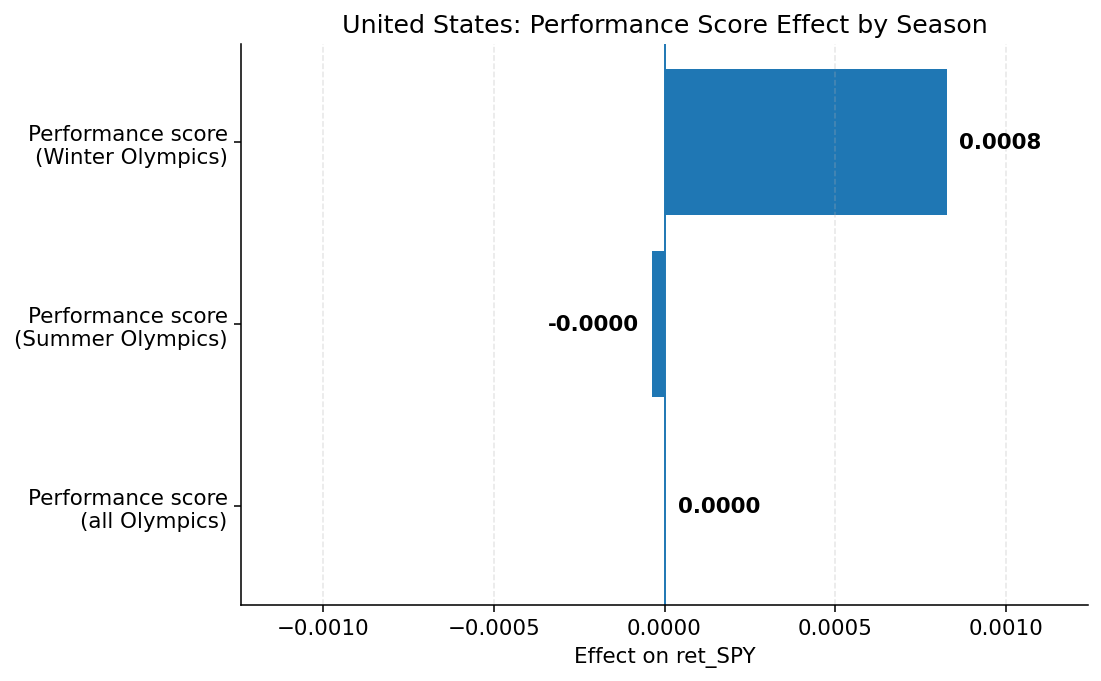


 New Zealand ret_NZ50
overall: 4.648923489451059e-05 summer: -0.0001127151303437 winter: 0.0010285968688916
core y values: ['ret_NZ50' 'lvc_NZ50' 'absret_NZ50' 'vol20_NZ50']
core term values: ['const' 'any_medal_dummy' 'dow_1' 'dow_2' 'dow_3' 'dow_4' 'month_2'
 'month_3' 'month_4' 'month_5' 'month_6' 'month_7' 'month_8' 'month_9'
 'month_10' 'month_11' 'month_12' 'performance_score' 'gold' 'silver']
season y values: ['ret_NZ50' 'lvc_NZ50' 'absret_NZ50' 'vol20_NZ50']
season term values: ['const' 'performance_score' 'winter_dummy' 'score_x_winter' 'dow_1'
 'dow_2' 'dow_3' 'dow_4' 'month_2' 'month_3' 'month_4' 'month_5' 'month_6'
 'month_7' 'month_8' 'month_9' 'month_10' 'month_11' 'month_12']


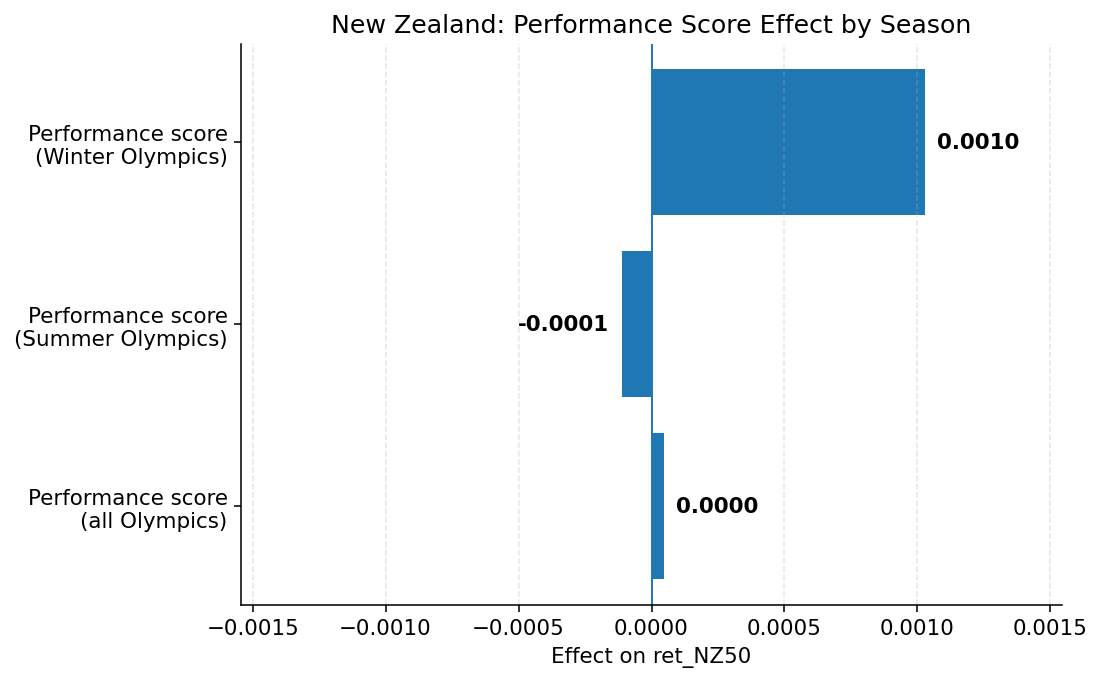

In [178]:
def extract_us_y_from_model(model_str):
    if pd.isna(model_str):
        return None
    s = str(model_str)
    return s.split("~")[0].strip() if "~" in s else None


def get_core_score_effect(core_df, metric):

    if core_df is None or core_df.empty:
        return np.nan, np.nan

    # Norway / New Zealand-style tables
    if {"y", "term", "coef"}.issubset(core_df.columns):

        sub = core_df[
            (core_df["y"] == metric) &
            (core_df["term"] == "performance_score")
        ]

        if "model" in sub.columns:
            pref = sub[sub["model"].str.contains("score_only", case=False, na=False)]
            if not pref.empty:
                sub = pref

        if sub.empty:
            return np.nan, np.nan

        r = sub.iloc[0]
        return float(r["coef"]), float(r.get("p", np.nan))

    # US-style tables
    if {"model", "param", "coef"}.issubset(core_df.columns):

        tmp = core_df.copy()
        tmp["y_inferred"] = tmp["model"].map(extract_us_y_from_model)

        sub = tmp[
            (tmp["y_inferred"] == metric) &
            (tmp["param"] == "performance_score")
        ]

        pref = sub[
            sub["model"].str.contains(r"score \+ ctrls", regex=True, na=False)
        ]

        pref = pref[
            ~pref["model"].str.contains("total\\+score", regex=True, na=False)
        ]

        if not pref.empty:
            sub = pref

        if sub.empty:
            return np.nan, np.nan

        r = sub.iloc[0]
        return float(r["coef"]), float(r.get("p", np.nan))

    return np.nan, np.nan


def get_season_effects(season_df, metric):

    if season_df is None or season_df.empty:
        return np.nan, np.nan, np.nan, np.nan

    # Norway / New Zealand-style
    if {"y", "term", "coef"}.issubset(season_df.columns):

        sub = season_df[season_df["y"] == metric]

        main = sub[sub["term"] == "performance_score"]
        inter = sub[sub["term"] == "score_x_winter"]

        if main.empty:
            return np.nan, np.nan, np.nan, np.nan

        main = main.iloc[0]

        main_coef = float(main["coef"])
        main_p = float(main.get("p", np.nan))

        if not inter.empty:
            inter = inter.iloc[0]
            inter_coef = float(inter["coef"])
            inter_p = float(inter.get("p", np.nan))
        else:
            inter_coef = 0
            inter_p = np.nan

        summer = main_coef
        winter = main_coef + inter_coef

        return summer, winter, main_p, inter_p

    # US-style
    if {"model", "param", "coef"}.issubset(season_df.columns):

        tmp = season_df.copy()
        tmp["y_inferred"] = tmp["model"].map(extract_us_y_from_model)

        sub = tmp[tmp["y_inferred"] == metric]

        main = sub[sub["param"] == "performance_score"]
        inter = sub[sub["param"] == "score_x_winter"]

        if main.empty:
            return np.nan, np.nan, np.nan, np.nan

        main = main.iloc[0]

        main_coef = float(main["coef"])
        main_p = float(main.get("p", np.nan))

        if not inter.empty:
            inter = inter.iloc[0]
            inter_coef = float(inter["coef"])
            inter_p = float(inter.get("p", np.nan))
        else:
            inter_coef = 0
            inter_p = np.nan

        summer = main_coef
        winter = main_coef + inter_coef

        return summer, winter, main_p, inter_p

    return np.nan, np.nan, np.nan, np.nan


targets = [
    ("norway", "Norway", "ret_OSEBX"),
    ("us", "United States", "ret_SPY"),
    ("nz", "New Zealand", "ret_NZ50"),
]

for prefix, country, metric in targets:

    if prefix not in result_files:
        print(f"No files for {country}")
        continue

    data = load_group(prefix)
    fig_dir = ensure_fig_dir(prefix)

    core_df = data.get("results_core_regressions_long.csv")
    season_df = data.get("results_season_interaction_long.csv")

    overall, p_overall = get_core_score_effect(core_df, metric)
    summer, winter, p_summer, p_inter = get_season_effects(season_df, metric)

    print("\n", country, metric)
    print("overall:", overall, "summer:", summer, "winter:", winter)

    if core_df is not None:
        print("core y values:", core_df["y"].dropna().unique()[:20] if "y" in core_df.columns else "no y col")
        print("core term values:", core_df["term"].dropna().unique()[:20] if "term" in core_df.columns else "no term col")

    if season_df is not None:
        print("season y values:", season_df["y"].dropna().unique()[:20] if "y" in season_df.columns else "no y col")
        print("season term values:", season_df["term"].dropna().unique()[:20] if "term" in season_df.columns else "no term col")

    plot_df = pd.DataFrame({
        "label": [
            "Performance score\n(all Olympics)",
            "Performance score\n(Summer Olympics)",
            "Performance score\n(Winter Olympics)"
        ],
        "coef": [overall, summer, winter]
    })

    fig, ax = plt.subplots(figsize=(8, 5))

    y = np.arange(len(plot_df))
    bars = ax.barh(y, plot_df["coef"])

    ax.axvline(0, linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(plot_df["label"])
    ax.set_xlabel(f"Effect on {metric}")
    ax.set_title(f"{country}: Performance Score Effect by Season")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

    coef_vals = pd.to_numeric(plot_df["coef"], errors="coerce").to_numpy()
    finite_vals = coef_vals[np.isfinite(coef_vals)]

    if finite_vals.size == 0:
        span = 0.001
    else:
        coef_max = finite_vals.max()
        coef_min = finite_vals.min()
        span = max(abs(coef_max), abs(coef_min)) * 1.5
        if span == 0:
            span = 0.001

    ax.set_xlim(-span, span)

    # place values just outside bars (always black)
    offset = span * 0.03

    for i, coef in enumerate(plot_df["coef"]):

        if pd.notna(coef):

            if coef >= 0:
                x_pos = coef + offset
                align = "left"
            else:
                x_pos = coef - offset
                align = "right"

            ax.text(
                x_pos,
                i,
                f"{coef:.4f}",
                ha=align,
                va="center",
                color="black",
                fontweight="bold"
            )

    plt.tight_layout()

    if prefix == "us":
        save_show(fig, fig_dir / f"{prefix}_05_performance_score_season_effects_{metric}.png")
    else:
        save_show(fig, fig_dir / f"{prefix}_04_performance_score_season_effects_{metric}.png")

    plt.show()

## 6. Optional: company-level sensitivity for one medal variable

This uses the same selected medal variable, but compares it across company-level models.


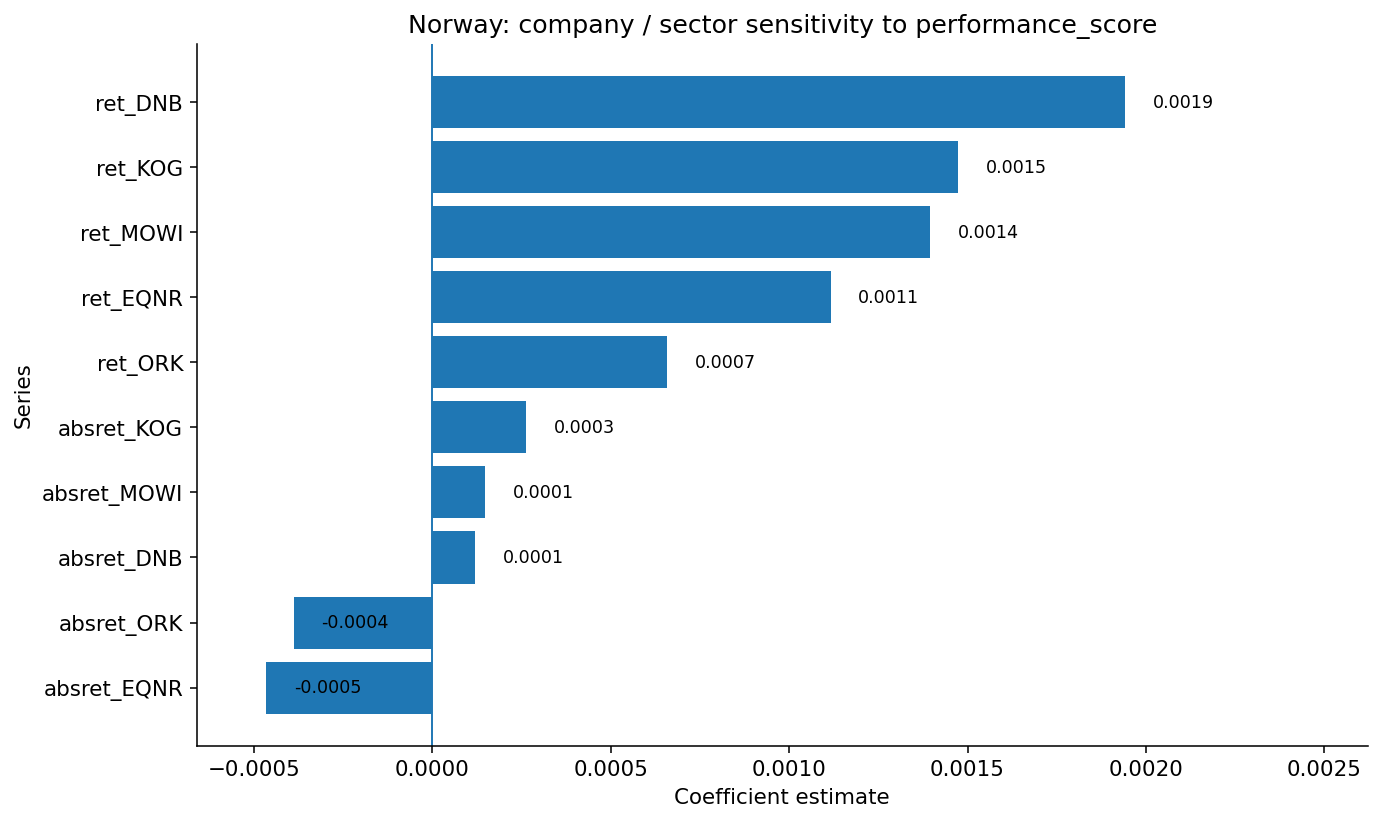

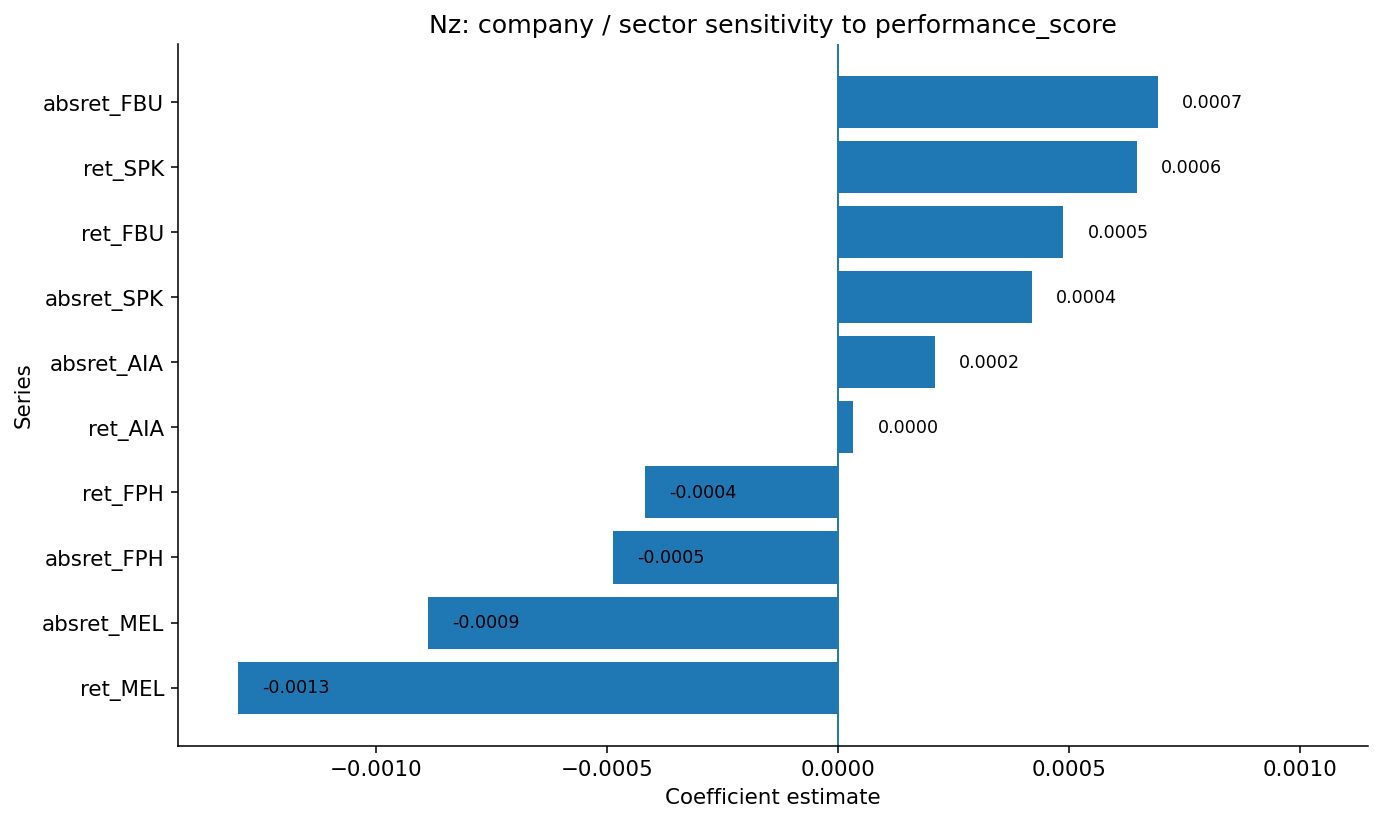

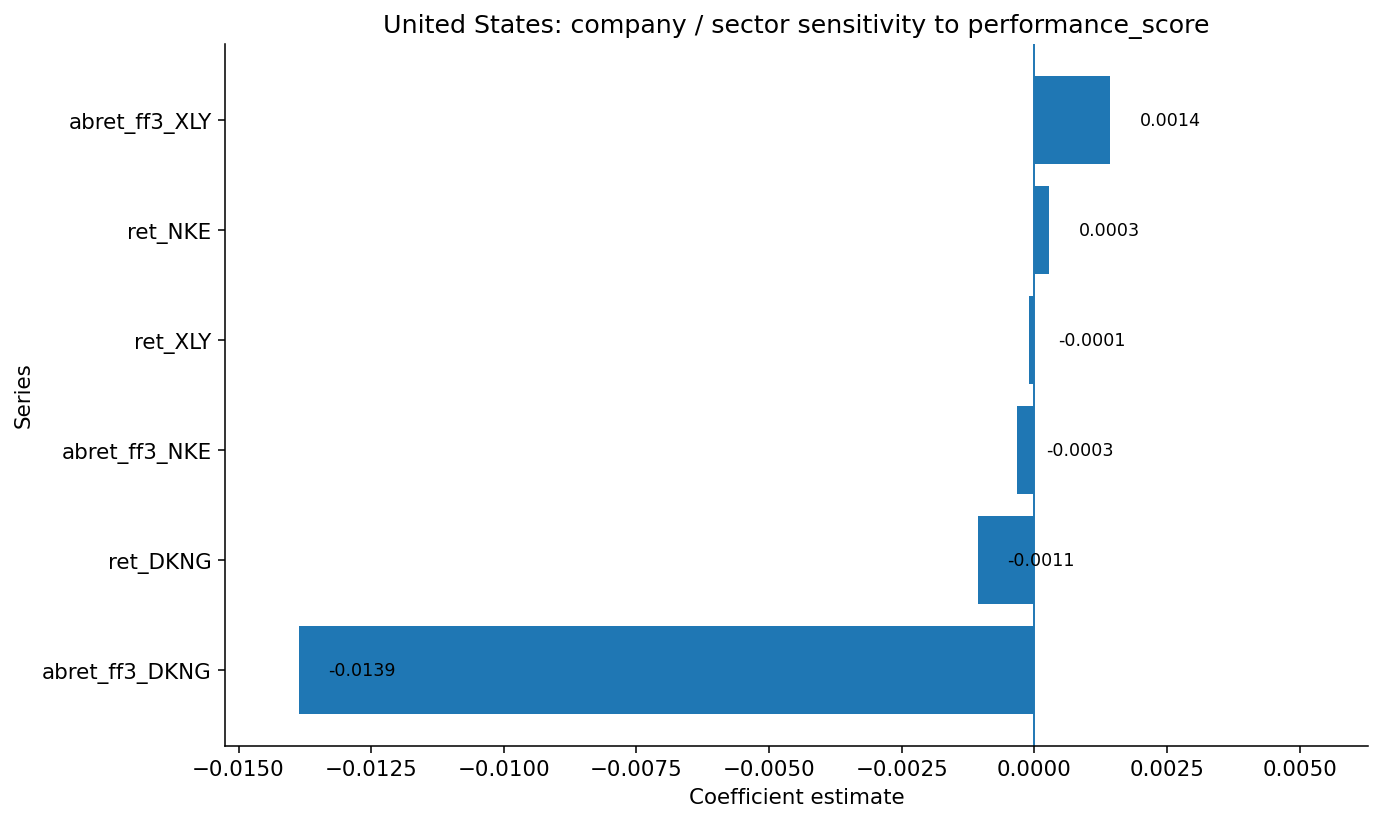

In [179]:
for prefix in sorted(result_files):
    cfg = country_config[prefix]
    country = cfg["country"]
    focus_term = cfg["term"]
    data = load_group(prefix)
    fig_dir = ensure_fig_dir(prefix)

    if "results_sector_regressions_long.csv" not in data or focus_term is None:
        continue

    sec = data["results_sector_regressions_long.csv"].copy()
    term_col = get_term_column(sec)
    if term_col is None or "coef" not in sec.columns:
        continue

    sec = sec[sec[term_col].astype(str) == str(focus_term)].copy()
    if sec.empty:
        continue

    if "y" in sec.columns:
        sec["series_name"] = sec["y"].astype(str)
    else:
        sec["series_name"] = sec["model"].astype(str).map(extract_y_from_model)

    sec["coef"] = pd.to_numeric(sec["coef"], errors="coerce")
    sec["p_num"] = pd.to_numeric(sec.get("p", np.nan), errors="coerce")
    sec = sec.dropna(subset=["coef", "series_name"]).copy()

    if "model" in sec.columns:
        preferred = sec[
            sec["model"].astype(str).str.contains(r"score \+ ctrls", regex=True, na=False)
        ].copy()
        if not preferred.empty:
            sec = preferred

    if sec["series_name"].duplicated().any():
        sec = sec.sort_values(
            by=["series_name", "p_num"],
            na_position="last"
        ).drop_duplicates(subset="series_name", keep="first")

    sec = sec.sort_values("coef").reset_index(drop=True)

    fig_height = max(6.0, 0.5 * len(sec))
    fig, ax = plt.subplots(figsize=(10, fig_height))

    bars = ax.barh(sec["series_name"], sec["coef"])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Coefficient estimate")
    ax.set_ylabel("Series")
    ax.set_title(f"{country}: company / sector sensitivity to {focus_term}")

    coef_min = sec["coef"].min()
    coef_max = sec["coef"].max()
    span = max(abs(coef_min), abs(coef_max))
    if span == 0:
        span = 0.001

    label_offset = span * 0.04
    right_pad = span * 0.35
    left_pad = span * 0.10
    ax.set_xlim(coef_min - left_pad, coef_max + right_pad)

    # one label per visible bar
    for y_i, (_, row) in enumerate(sec.iterrows()):
        coef = row["coef"]
        x_pos = coef + label_offset
        ax.text(
            x_pos,
            y_i,
            f"{coef:.4f}",
            ha="left",
            va="center",
            fontsize=9,
            color="black"
        )

    if prefix == "us":
        save_show(fig, fig_dir / f"{prefix}_06_sector_sensitivity_{focus_term}.png")
    else:
        save_show(fig, fig_dir / f"{prefix}_05_sector_sensitivity_{focus_term}.png")


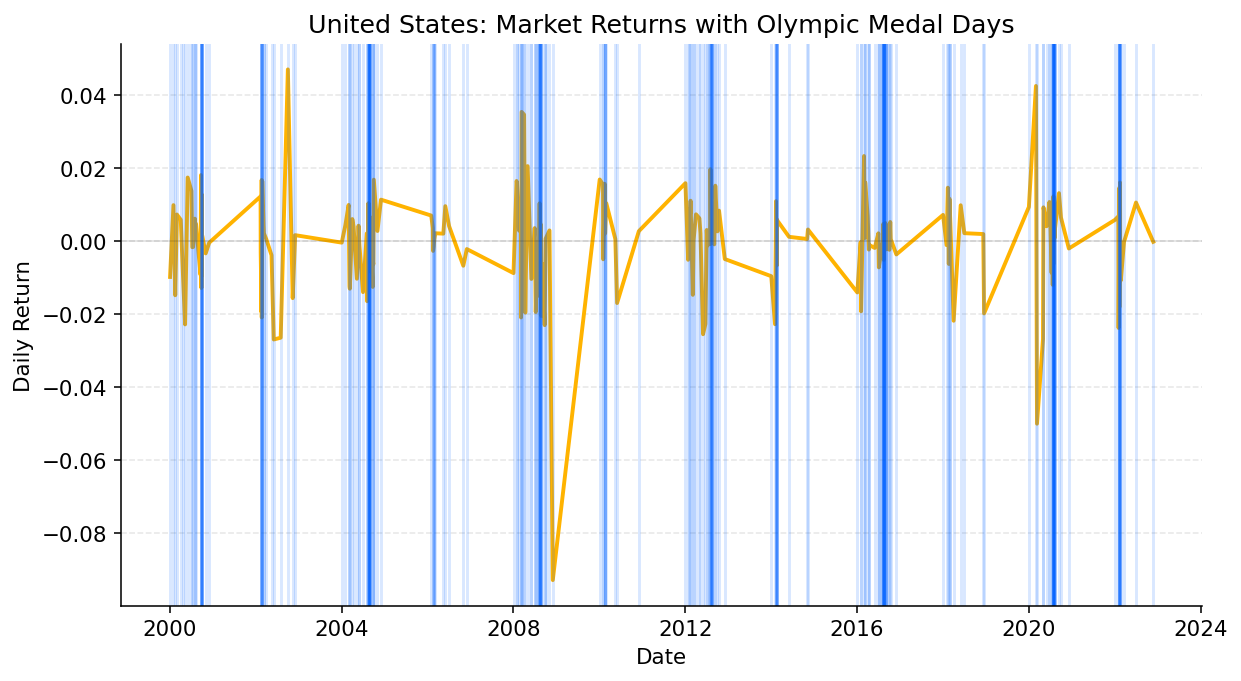

In [180]:
merged_us = pd.read_csv("../data/interim/usa/usa_medals_market_panel.csv")

merged_us["trade_date"] = pd.to_datetime(merged_us["trade_date"])

fig, ax = plt.subplots(figsize=(9,5))

ax.plot(
    merged_us["trade_date"],
    merged_us["ret_SPY"],
    color="#ffb300",   # deep navy
    linewidth=2.0,
    label="SPY Daily Return"
)

medal_days = merged_us.loc[merged_us["any_medal_dummy"] == 1, "trade_date"]

for d in medal_days:
    ax.axvline(d, alpha=0.15, color="#0062FF")  # Olympic gold

ax.axhline(0, linewidth=0.1, color="black")

ax.set_title("United States: Market Returns with Olympic Medal Days")
ax.set_ylabel("Daily Return")
ax.set_xlabel("Date")

ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()

fig_dir = ensure_fig_dir("us")
save_show(fig, fig_dir / "us_market_returns_with_medal_days.png")

plt.show()

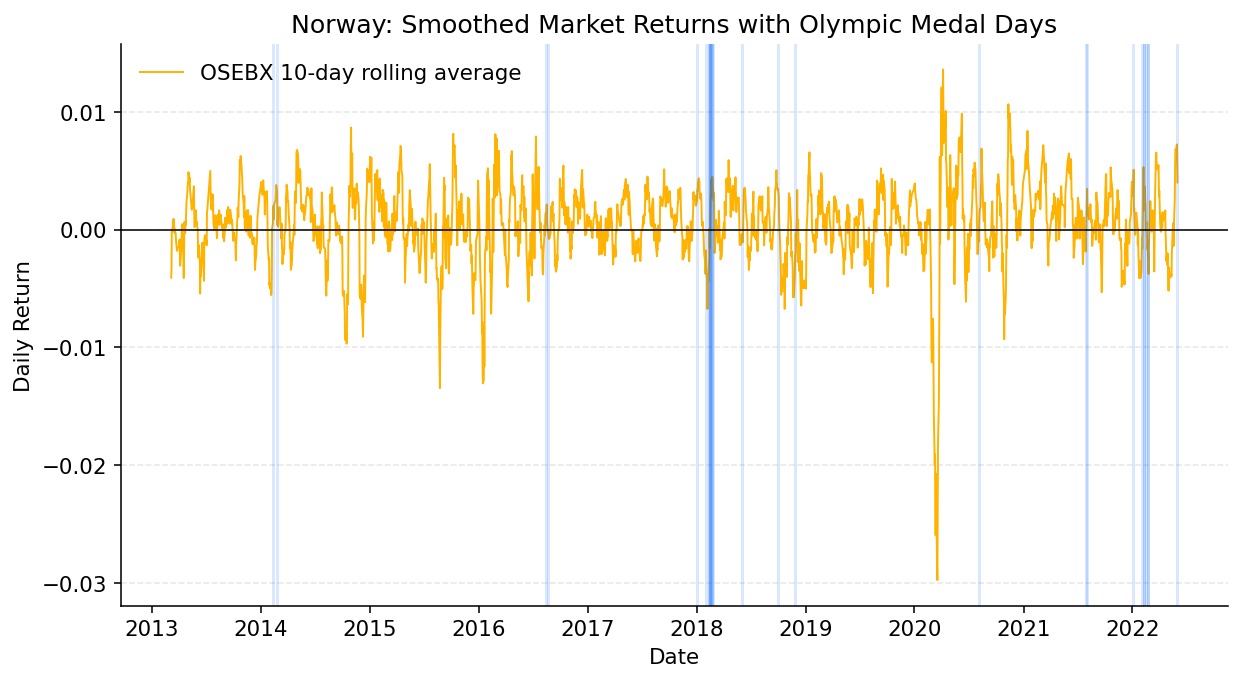

In [181]:
merged_no = pd.read_csv("../data/interim/norway/norway_medals_market_panel.csv")

merged_no["trade_date"] = pd.to_datetime(merged_no["trade_date"])
merged_no["ret_OSEBX"] = pd.to_numeric(merged_no["ret_OSEBX"], errors="coerce")

# keep only dates where market return data actually exists
merged_no = merged_no.dropna(subset=["ret_OSEBX"]).copy()

# smooth the series to reduce volatility noise
rolling_window = 10
merged_no["ret_OSEBX_smooth"] = merged_no["ret_OSEBX"].rolling(rolling_window, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(9,5))

ax.plot(
    merged_no["trade_date"],
    merged_no["ret_OSEBX_smooth"],
    color="#ffb300",
    linewidth=1.0,
    label=f"OSEBX {rolling_window}-day rolling average"
)

medal_days = merged_no.loc[merged_no["any_medal_dummy"] == 1, "trade_date"]

for d in medal_days:
    ax.axvline(d, alpha=0.15, color="#0062FF")

ax.axhline(0, linewidth=0.8, color="black")

ax.set_title("Norway: Smoothed Market Returns with Olympic Medal Days")
ax.set_ylabel("Daily Return")
ax.set_xlabel("Date")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=False)

plt.tight_layout()

fig_dir = ensure_fig_dir("norway")
save_show(fig, fig_dir / "norway_market_returns_with_medal_days.png")

plt.show()

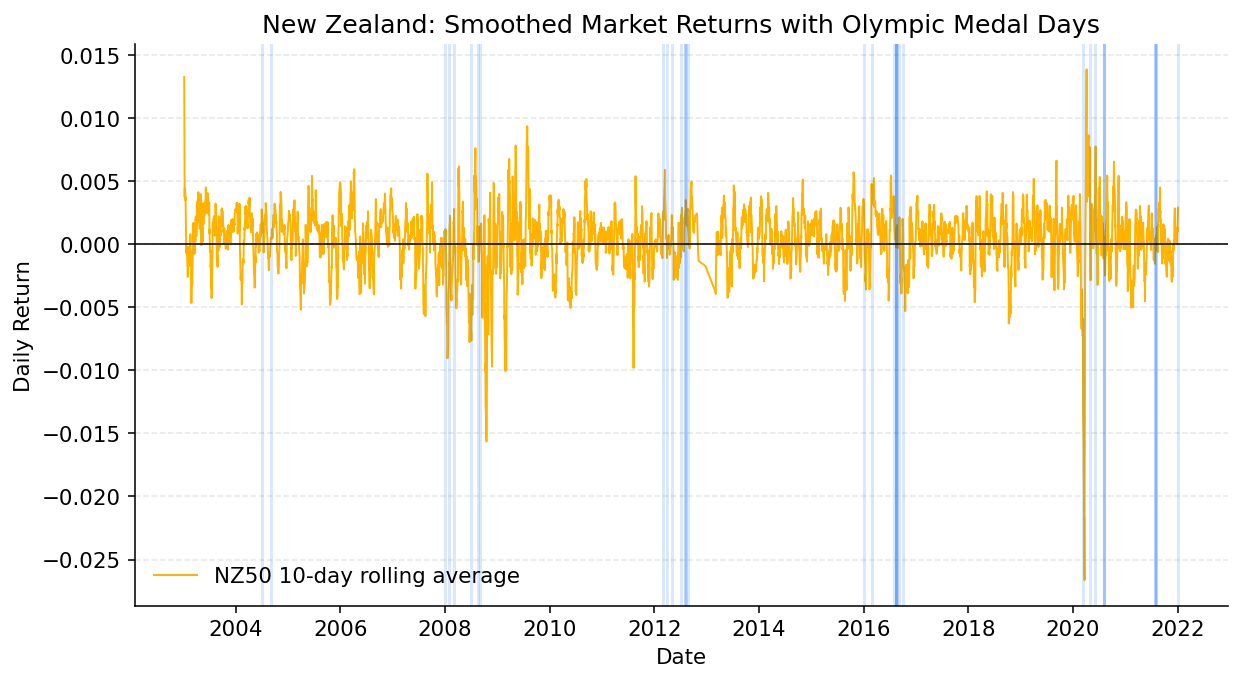

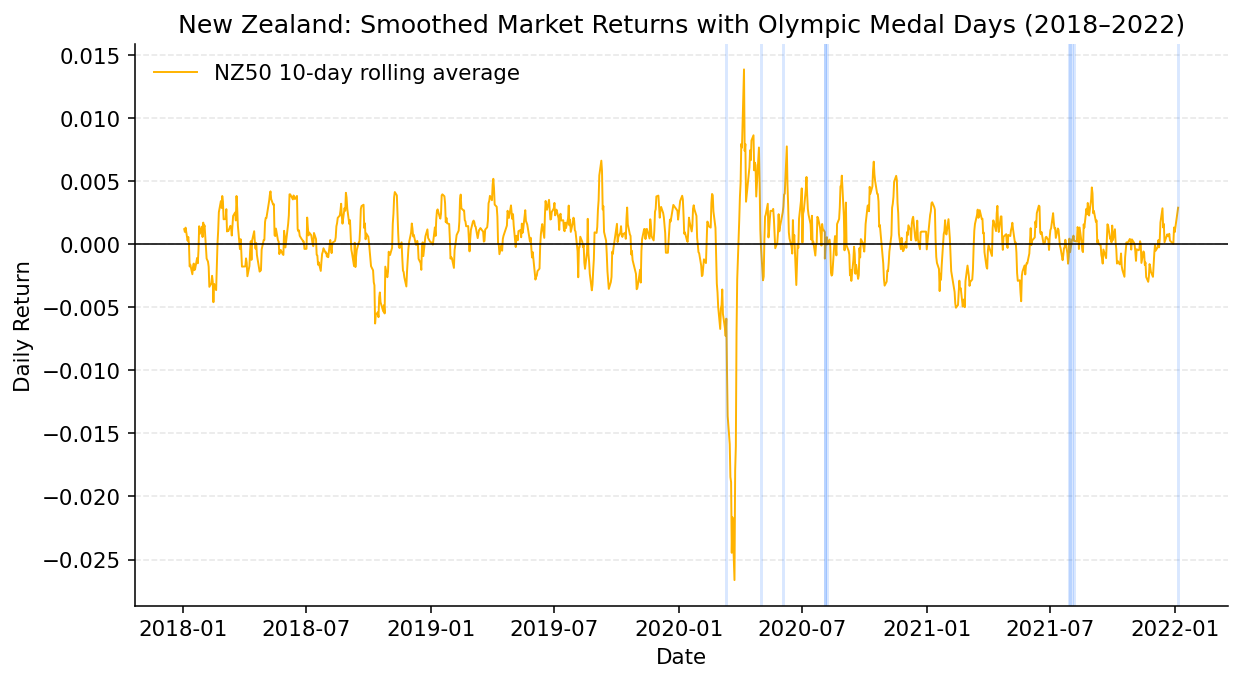

In [182]:
merged_nz = pd.read_csv("../data/interim/nz/nz_medals_market_panel.csv")

merged_nz["trade_date"] = pd.to_datetime(merged_nz["trade_date"])
merged_nz["ret_NZ50"] = pd.to_numeric(merged_nz["ret_NZ50"], errors="coerce")

# keep only dates where market return data actually exists
merged_nz = merged_nz.dropna(subset=["ret_NZ50"]).copy()

# smooth the series to reduce volatility noise
rolling_window = 10
merged_nz["ret_NZ50_smooth"] = merged_nz["ret_NZ50"].rolling(rolling_window, min_periods=1).mean()

fig_dir = ensure_fig_dir("nz")

# -----------------------------
# Full-range graph
# -----------------------------
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    merged_nz["trade_date"],
    merged_nz["ret_NZ50_smooth"],
    color="#ffb300",
    linewidth=1.0,
    label=f"NZ50 {rolling_window}-day rolling average"
)

medal_days = merged_nz.loc[merged_nz["any_medal_dummy"] == 1, "trade_date"]

for d in medal_days:
    ax.axvline(d, alpha=0.15, color="#0062FF")

ax.axhline(0, linewidth=0.8, color="black")

ax.set_title("New Zealand: Smoothed Market Returns with Olympic Medal Days")
ax.set_ylabel("Daily Return")
ax.set_xlabel("Date")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=False)

plt.tight_layout()
save_show(fig, fig_dir / "nz_market_returns_with_medal_days.png")
plt.show()

# -----------------------------
# Zoomed graph: 2018 to 2022
# -----------------------------
zoom_start = pd.Timestamp("2018-01-01")
zoom_end = pd.Timestamp("2022-12-31")

merged_nz_zoom = merged_nz[
    (merged_nz["trade_date"] >= zoom_start) &
    (merged_nz["trade_date"] <= zoom_end)
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    merged_nz_zoom["trade_date"],
    merged_nz_zoom["ret_NZ50_smooth"],
    color="#ffb300",
    linewidth=1.0,
    label=f"NZ50 {rolling_window}-day rolling average"
)

zoom_medal_days = merged_nz_zoom.loc[merged_nz_zoom["any_medal_dummy"] == 1, "trade_date"]

for d in zoom_medal_days:
    ax.axvline(d, alpha=0.15, color="#0062FF")

ax.axhline(0, linewidth=0.8, color="black")

ax.set_title("New Zealand: Smoothed Market Returns with Olympic Medal Days (2018–2022)")
ax.set_ylabel("Daily Return")
ax.set_xlabel("Date")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(frameon=False)

plt.tight_layout()
save_show(fig, fig_dir / "nz_market_returns_with_medal_days_2018_2022.png")
plt.show()

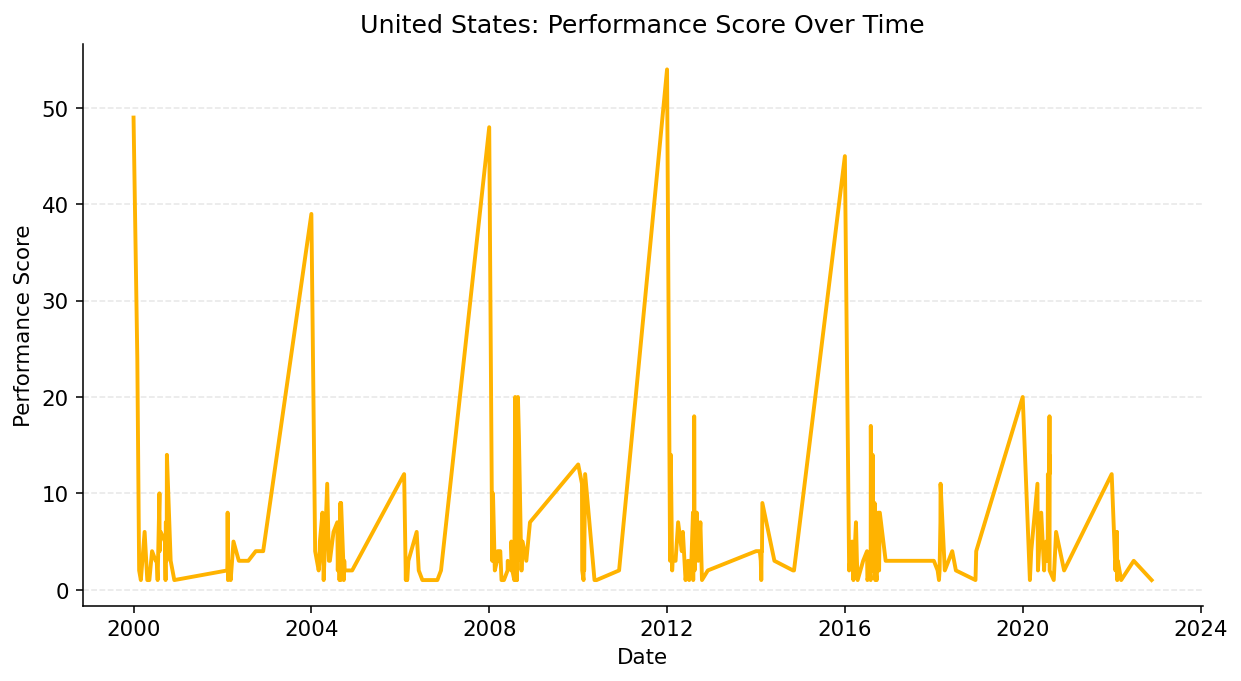

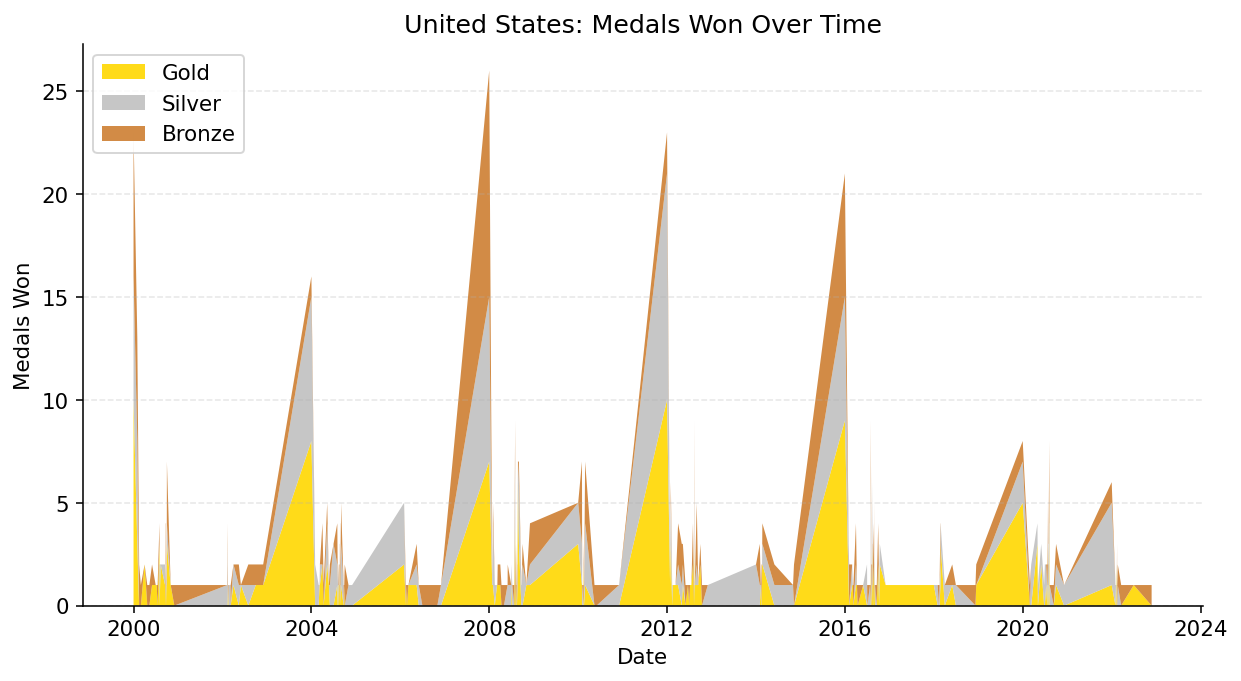

In [183]:
us_daily = pd.read_csv("../data/interim/usa/usa_medal_daily_counts_and_score_ALL.csv")
us_daily["event_date_end"] = pd.to_datetime(us_daily["event_date_end"])

# Performance score over time
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    us_daily["event_date_end"],
    us_daily["performance_score"],
    color="#ffb300",
    linewidth=2.0
)

ax.set_title("United States: Performance Score Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Performance Score")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
fig_dir = ensure_fig_dir("us")
save_show(fig, fig_dir / "us_performance_score_over_time.png")

# Stacked medals over time
fig, ax = plt.subplots(figsize=(9, 5))

ax.stackplot(
    us_daily["event_date_end"],
    us_daily["gold"],
    us_daily["silver"],
    us_daily["bronze"],
    labels=["Gold", "Silver", "Bronze"],
    colors=["#FFD700", "#C0C0C0", "#CD7F32"],
    alpha=0.9
)

ax.set_title("United States: Medals Won Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Medals Won")
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
save_show(fig, fig_dir / "us_medals_stacked_over_time.png")

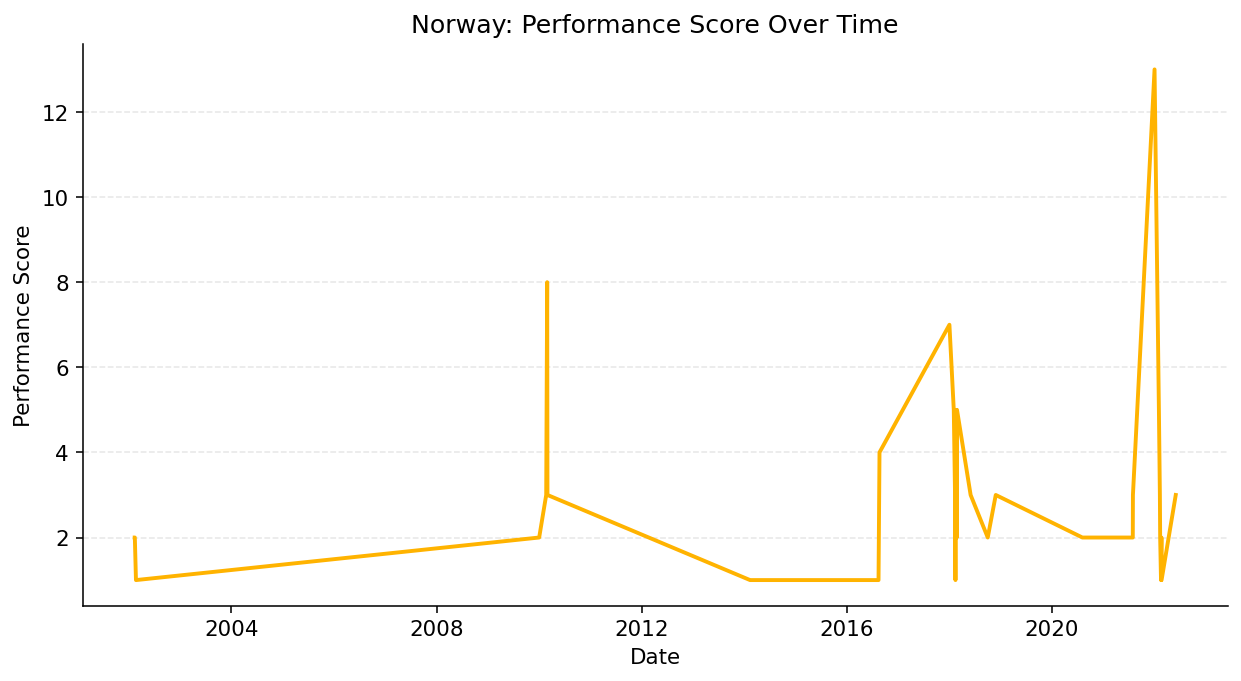

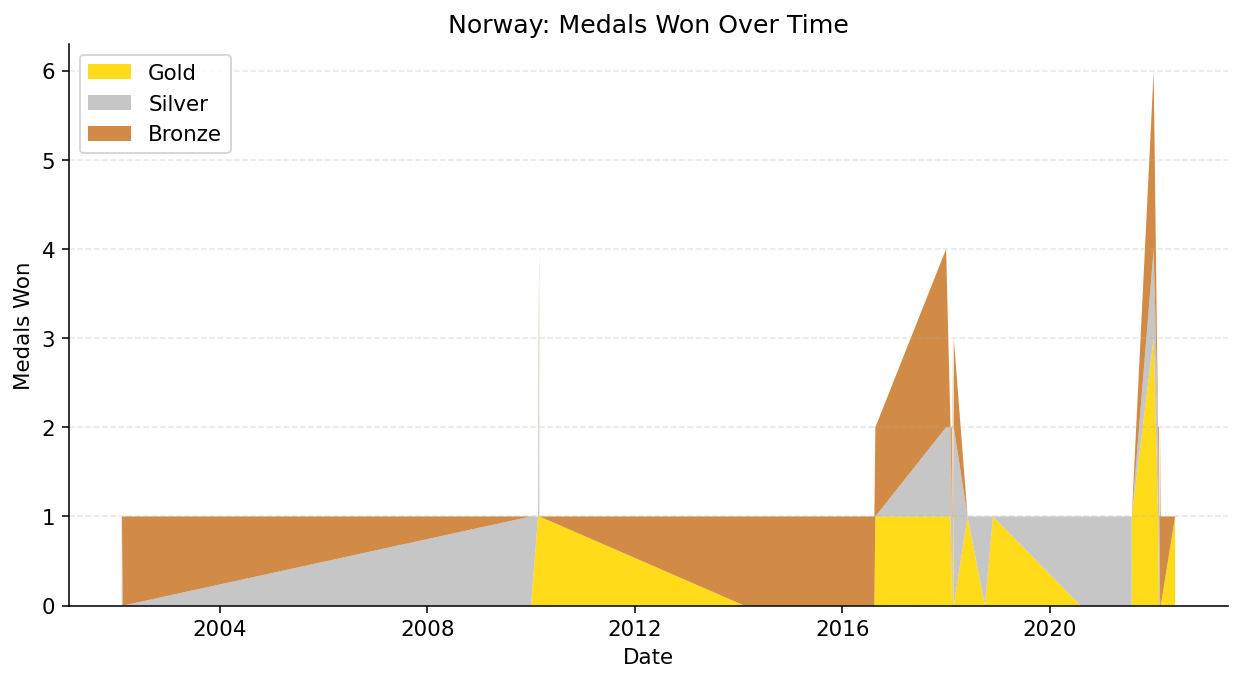

In [184]:
norway_daily = pd.read_csv("../data/interim/norway/norway_medal_daily_counts_and_score_ALL.csv")
norway_daily["event_date_end"] = pd.to_datetime(norway_daily["event_date_end"])

# Performance score over time
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    norway_daily["event_date_end"],
    norway_daily["performance_score"],
    color="#ffb300",
    linewidth=2.0
)

ax.set_title("Norway: Performance Score Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Performance Score")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
fig_dir = ensure_fig_dir("norway")
save_show(fig, fig_dir / "norway_performance_score_over_time.png")

# Stacked medals over time
fig, ax = plt.subplots(figsize=(9, 5))

ax.stackplot(
    norway_daily["event_date_end"],
    norway_daily["gold"],
    norway_daily["silver"],
    norway_daily["bronze"],
    labels=["Gold", "Silver", "Bronze"],
    colors=["#FFD700", "#C0C0C0", "#CD7F32"],
    alpha=0.9
)

ax.set_title("Norway: Medals Won Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Medals Won")
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
save_show(fig, fig_dir / "norway_medals_stacked_over_time.png")

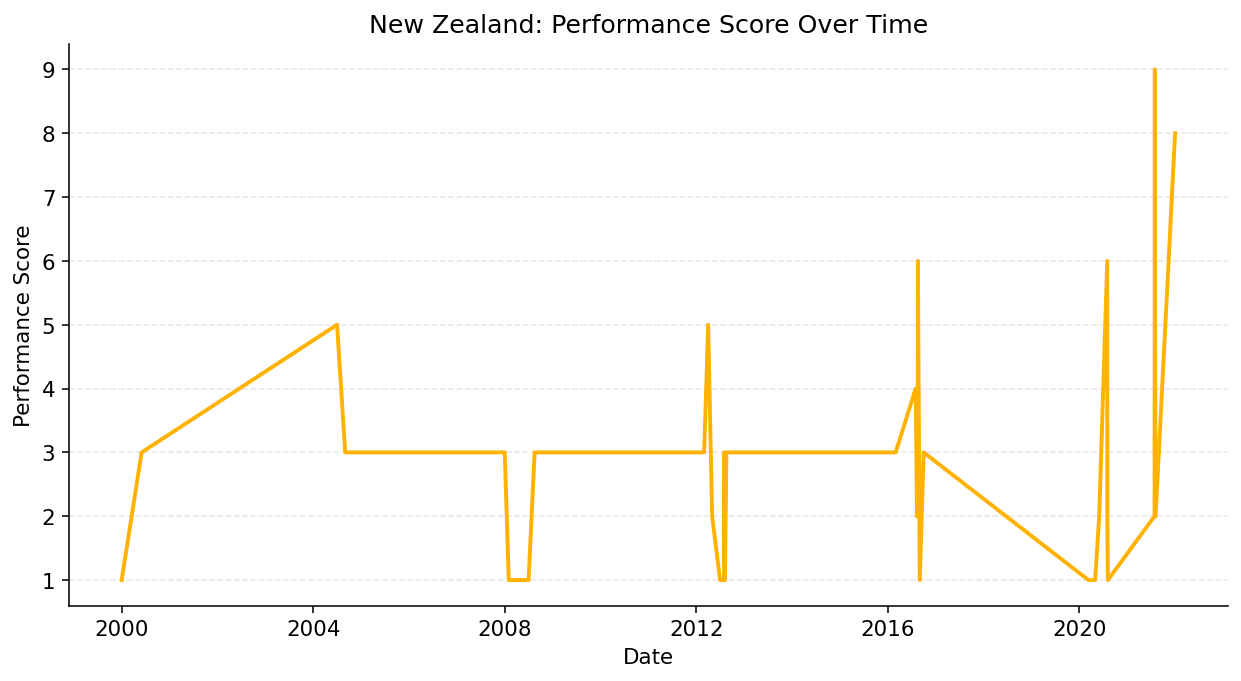

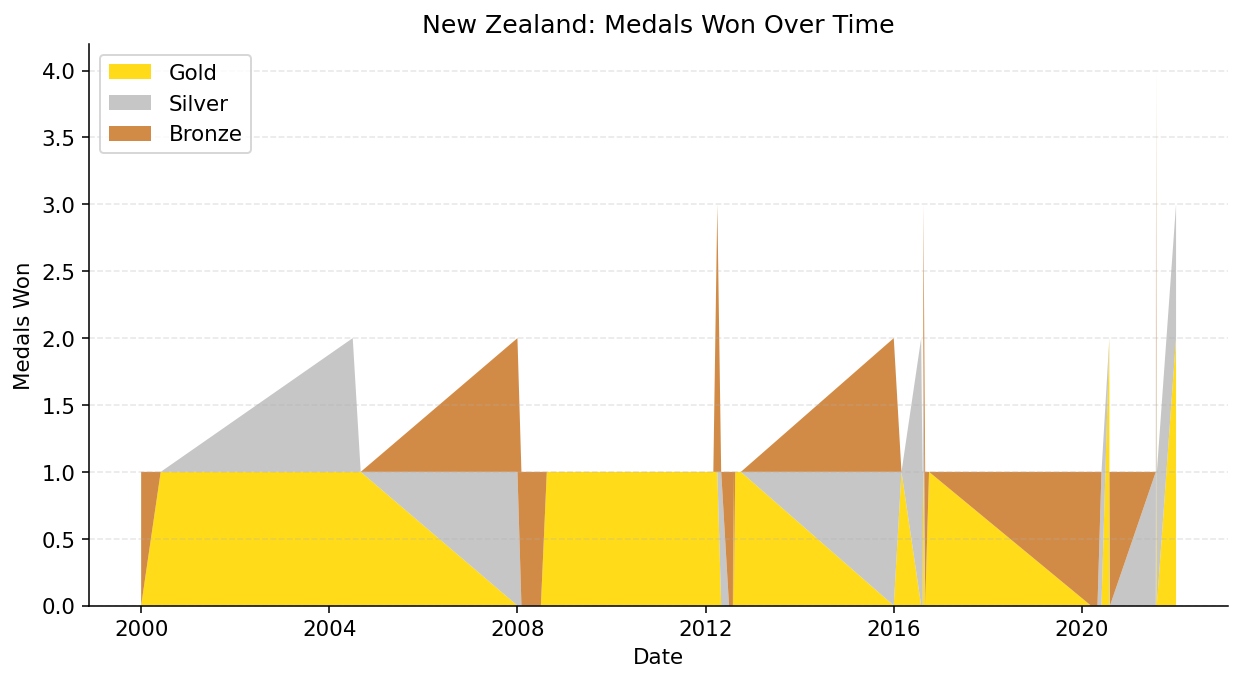

In [185]:
nz_daily = pd.read_csv("../data/interim/nz/nz_medal_daily_counts_and_score_ALL.csv")
nz_daily["event_date_end"] = pd.to_datetime(nz_daily["event_date_end"])

# Performance score over time
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    nz_daily["event_date_end"],
    nz_daily["performance_score"],
    color="#ffb300",
    linewidth=2.0
)

ax.set_title("New Zealand: Performance Score Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Performance Score")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
fig_dir = ensure_fig_dir("nz")
save_show(fig, fig_dir / "nz_performance_score_over_time.png")

# Stacked medals over time
fig, ax = plt.subplots(figsize=(9, 5))

ax.stackplot(
    nz_daily["event_date_end"],
    nz_daily["gold"],
    nz_daily["silver"],
    nz_daily["bronze"],
    labels=["Gold", "Silver", "Bronze"],
    colors=["#FFD700", "#C0C0C0", "#CD7F32"],
    alpha=0.9
)

ax.set_title("New Zealand: Medals Won Over Time")
ax.set_xlabel("Date")
ax.set_ylabel("Medals Won")
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
save_show(fig, fig_dir / "nz_medals_stacked_over_time.png")